In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

import pylimma 
import decoupler as dc 
import gseapy as gp 
from gseapy.base import GMT

from datasets.Harmonized_Datasets import harmonize 
from model_testing import external_validation


import pickle
import os

/home/braemp4/.cache/pypoetry/virtualenvs/venetoclax-project-Qra0yt8T-py3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
GMT_DIR = "../../data/GMT/"

In [4]:

def differential_expression_analysis(expr, metadata, group_label='y_pred'):
    ''' 
    adata needs group_label column
    '''
    
    analysis_results = {'gene':None, 't': None, 'padj':None}

    
    design = np.column_stack([np.ones( len(metadata[group_label]) ), np.array(metadata[group_label]) ])
    fit = pylimma.lm_fit(expr.transpose(), design)
    fit = pylimma.contrasts_fit(fit, contrasts=np.array([[0], [1]]))
    fit = pylimma.e_bayes(fit)

    results_df = pylimma.top_table(fit,coef=0, key="fit",number=np.inf,sort_by="p")
    results_df['padj'] = results_df["adj_p_value"]

    analysis_results['gene'] = results_df.index 
    analysis_results['t'] = results_df['t']
    analysis_results['padj'] = results_df['padj']
    analysis_results['log_fc'] = results_df['log_fc']
        
   

    analysis_results = pd.DataFrame(analysis_results)

    fig, ax = plt.subplots(1, figsize=(20,20))
    dc.pl.volcano(data=analysis_results, x="log_fc", y="padj", top=30, ax=ax)
    plt.show()
    return  analysis_results.set_index('gene')

In [5]:
with open("../../models/best_model.pkl", 'rb') as f:
    model = pickle.load(f)

In [6]:
adatas = harmonize()

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


DeCampos Annotated data found!
Number of Harmonized Genes: 18672


In [7]:
mf_ad = adatas['Moffitt']
dc_ad = adatas['Decampos']

In [8]:
cv_results = pd.read_csv('../../outputs/best_model_cv_predictions.csv').set_index('samples')
ev_results = pd.DataFrame(external_validation(model)).drop('samples', axis=1)

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


DeCampos Annotated data found!
Number of Harmonized Genes: 18672


/home/braemp4/code/venetoclax_project/src/model_testing.py:11: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['venetoclax_response'] = binarize_labels(adata.obs['ABT-199'])


In [9]:
cv_results['t11_14'] = mf_ad.obs.loc[cv_results.index]['t11_14']

**Grab genesets for GSEA**

In [10]:
feature_sets = {
        #'all': list(mf_ad.to_df().columns),
        'Gupta_six_gene_signature': ['VPREB3', 'CCR7', 'SORL1', 'TRABD2A', 'EFEMP1', 'TDO2'], 
      
        # novel data-driven (i.e. t11;14 degs from commpass)
        't11_14_degs': [],

      
        }

with open("../../outputs/t11_14_degs.txt", "r") as file:
    feature_sets['t11_14_degs'] = file.read().split(',')




for file_name in os.listdir(GMT_DIR):
    if 'gmt' in file_name:
        if "ZHAN" in file_name or "TART" in file_name or "HAY" in file_name or "SHAF" in file_name or "BCL" in file_name or 'chr' in file_name: 
            gmt = gp.read_gmt(GMT_DIR + file_name)            
            feature_sets[file_name] = list(gmt.values())[0]


In [11]:
feature_sets

{'Gupta_six_gene_signature': ['VPREB3',
  'CCR7',
  'SORL1',
  'TRABD2A',
  'EFEMP1',
  'TDO2'],
 't11_14_degs': ['TBC1D3B',
  'MAGEB2',
  'TSPY9',
  'YTHDC1',
  'GAGE12F',
  'LRRC26',
  'MUC15',
  'PPP4R3C',
  'TRAM1L1',
  'SMIM33',
  'NFKBIL1',
  'CDK20',
  'GAGE13',
  'KCNK15',
  'HPGD',
  'CTAG1A',
  'KCNA5',
  'ZC2HC1B',
  'TSPY10',
  'GIPC3',
  'LGALS12',
  'OPN5',
  'GRID2',
  'CXCR5',
  'TMC4',
  'PTGFR',
  'MAGEA6',
  'ADGRL3',
  'MS4A1',
  'CADM2',
  'VXN',
  'ELFN1',
  'KRT7',
  'CTTNBP2',
  'PAGE5',
  'DCAF8L2',
  'FIGNL2',
  'PROX1',
  'CLEC11A',
  'PCDH10',
  'CLDN3',
  'RAMP3',
  'MAJIN',
  'CXCL3',
  'SPON1',
  'FOXD1',
  'AZGP1',
  'MALRD1',
  'HAT1',
  'DCAF4L2',
  'NTNG1',
  'IGFBP3',
  'SLITRK2',
  'OCSTAMP',
  'C6orf52',
  'RBPMS2',
  'NKAIN2',
  'CDHR1',
  'EMILIN3',
  'GAGE2A',
  'MC5R',
  'SHISA3',
  'LSP1',
  'ZFP28',
  'CTSW',
  'EPHA2',
  'TCP11X2',
  'MAL',
  'TLE6',
  'SPNS3',
  'C5orf58',
  'FIGN',
  'NLGN4X',
  'COL5A1',
  'PKP3',
  'NRCAM',
  'SDK2',
  '

**Analyzing CV Results**


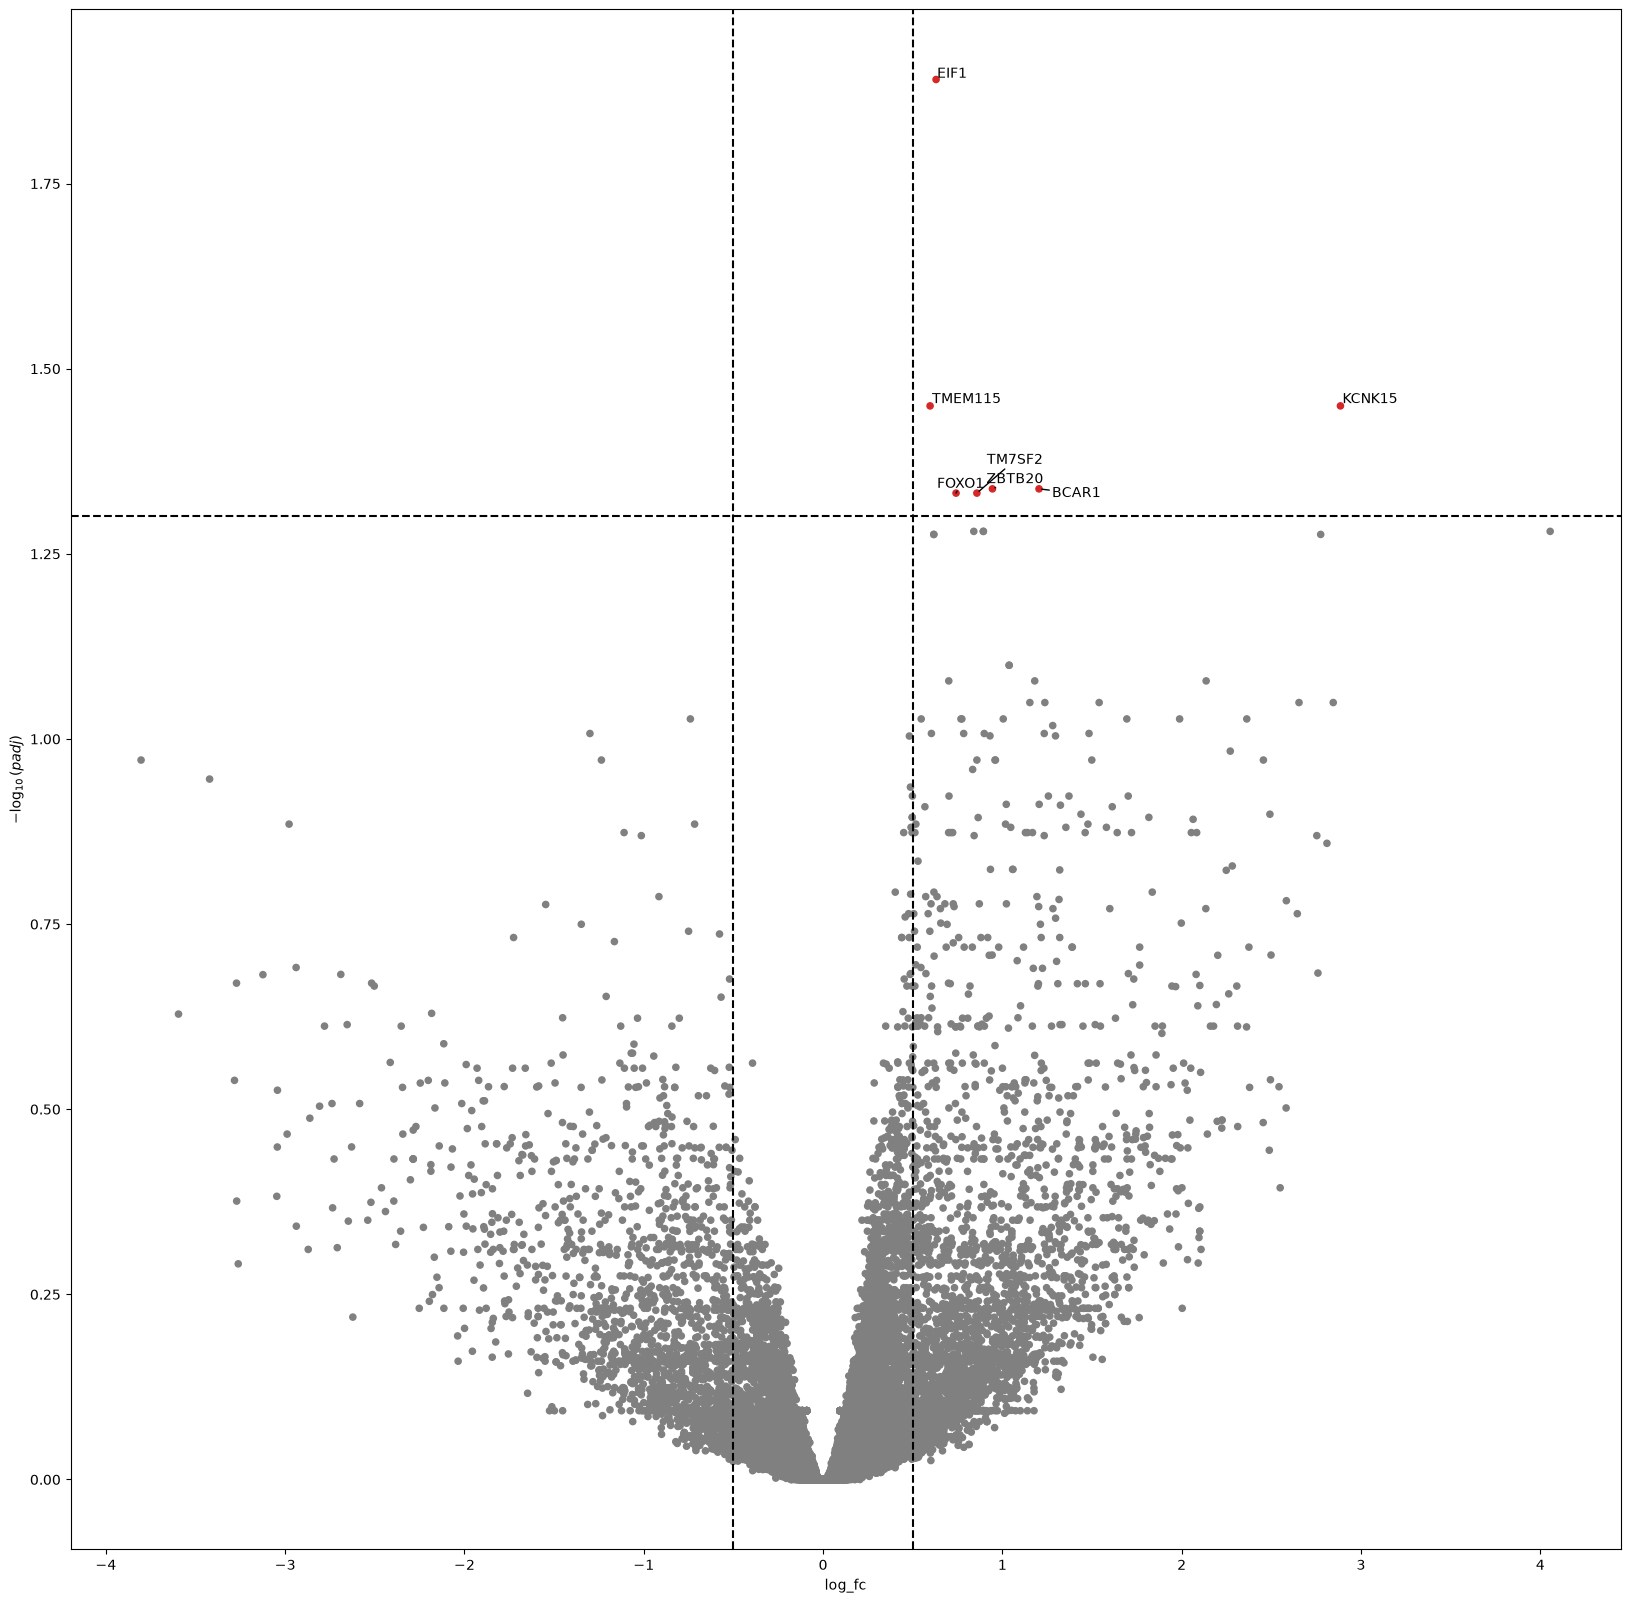

2026-11-04 16:57:55,732 [WARNING] Duplicated values found in preranked stats:
sample	ratio
t         4.43%
padj     81.84%
log_fc    4.98%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'True Sensitive vs. Resistant'}, xlabel='NES'>

<Figure size 640x480 with 0 Axes>

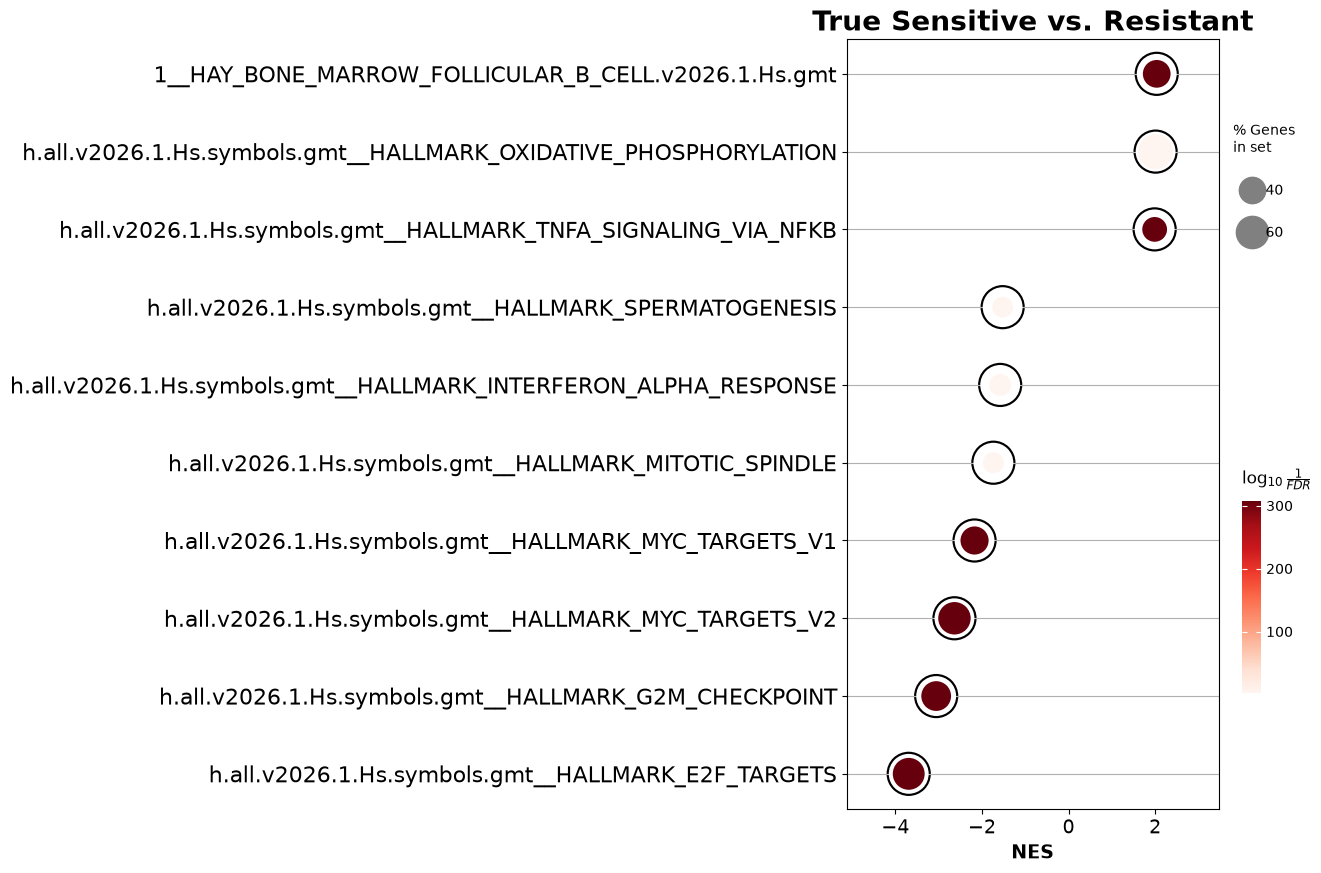

In [ ]:
degs_true_labels = differential_expression_analysis(mf_ad.to_df().loc[cv_results.index], cv_results, group_label='y_true')
degs_true_labels

hallmark_gmt = GMT_DIR + "h.all.v2026.1.Hs.symbols.gmt"
msig_gmt = GMT_DIR + 'msigdb.v2026.1.Hs.symbols.gmt'

degs_true_labels = degs_true_labels.sort_values(by="t")
pre_res = gp.prerank(rnk=degs_true_labels, gene_sets=[hallmark_gmt, feature_sets, msig_gmt], threads=8, min_size=5, max_size=1500, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")

plt.clf()
gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='True Sensitive vs. Resistant', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True)

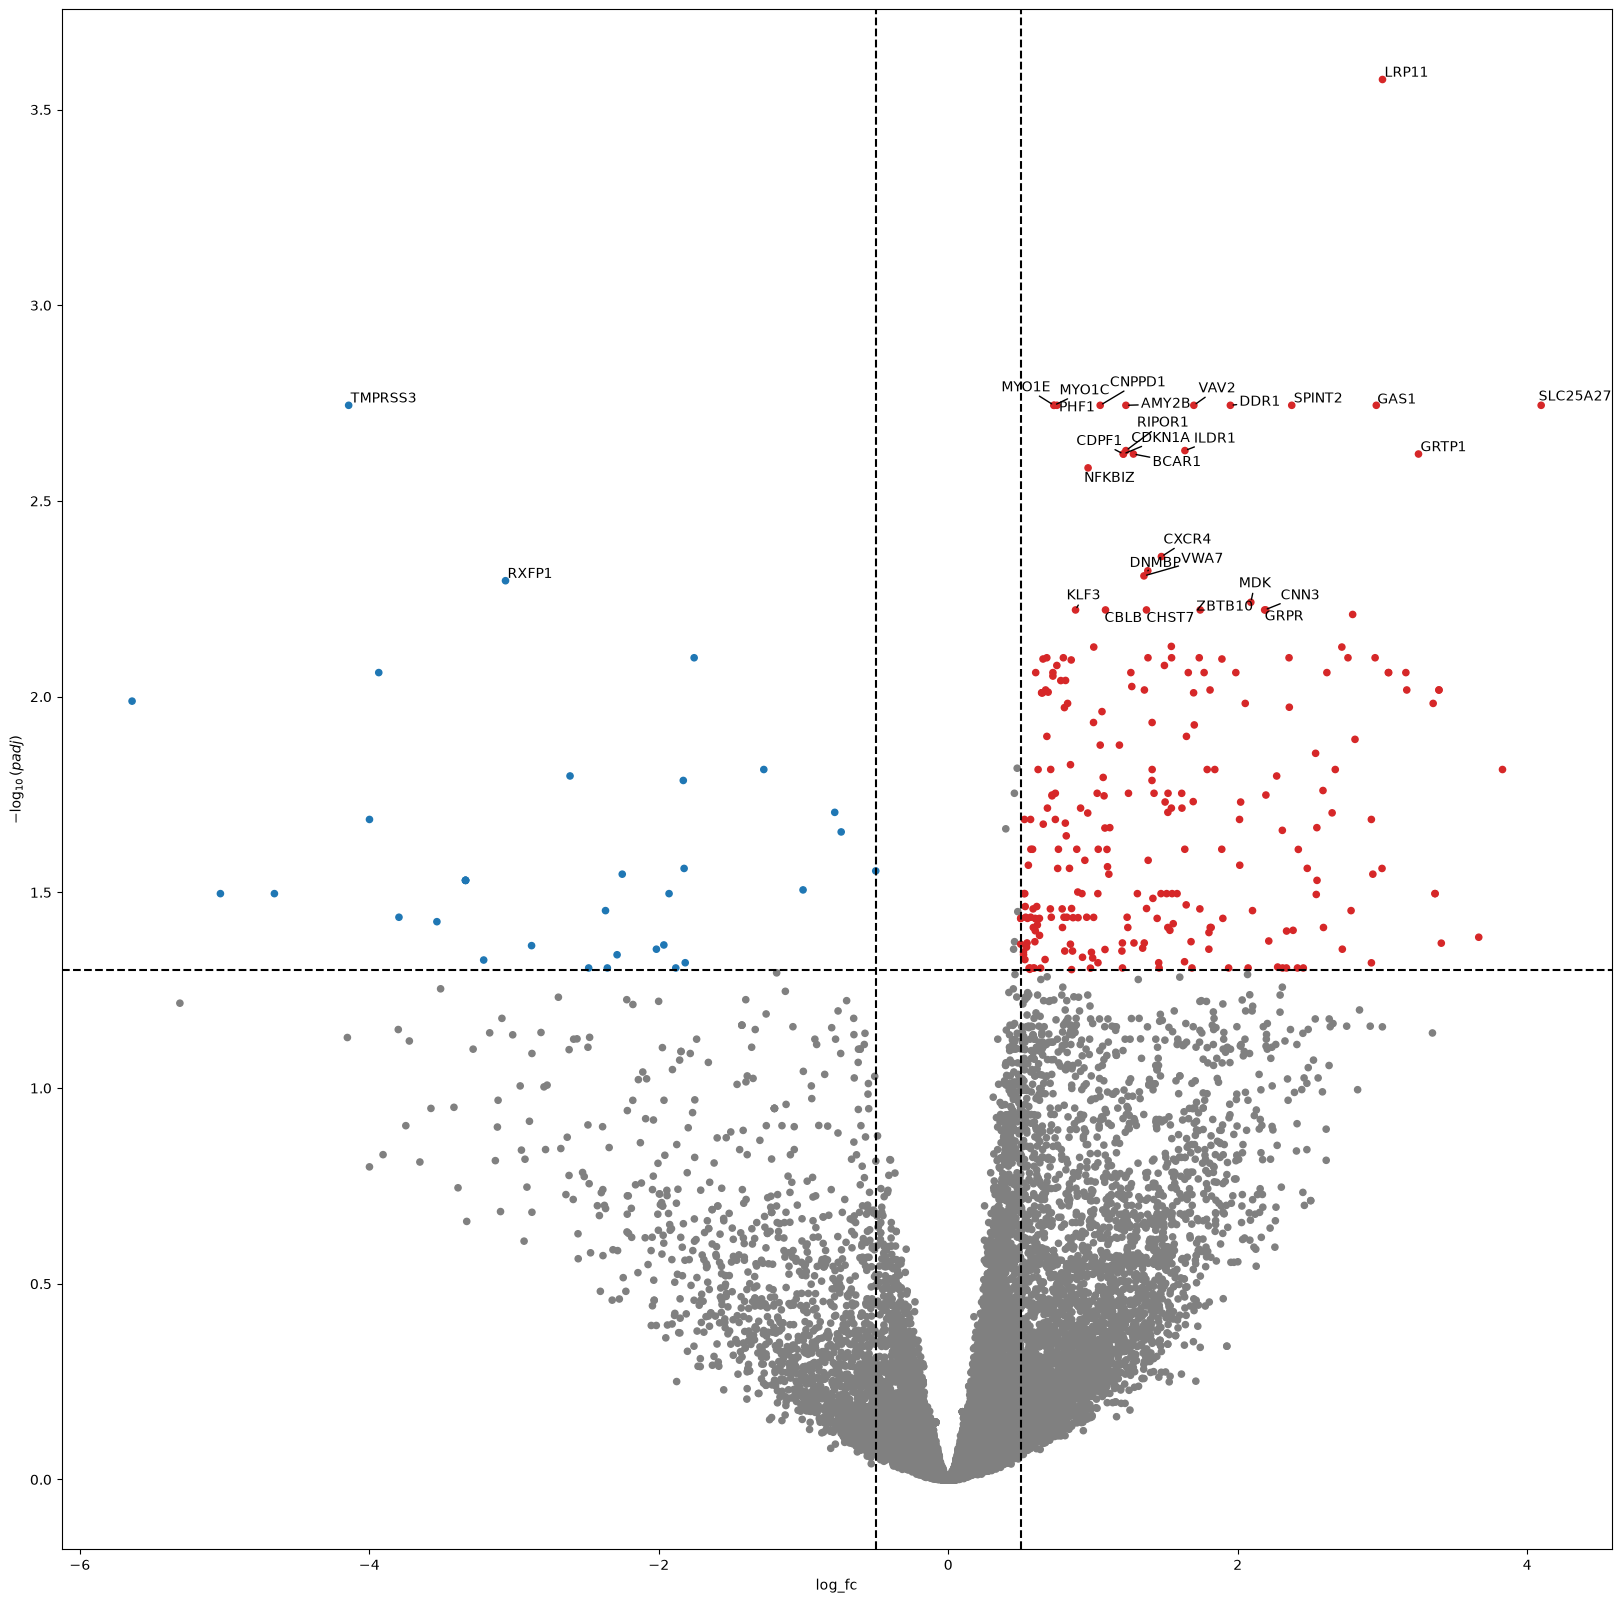

2026-11-04 16:58:09,758 [WARNING] Duplicated values found in preranked stats:
sample	ratio
t         4.45%
padj     65.98%
log_fc    4.81%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'Predicted Sensitive vs. Resistant'}, xlabel='NES'>

<Figure size 640x480 with 0 Axes>

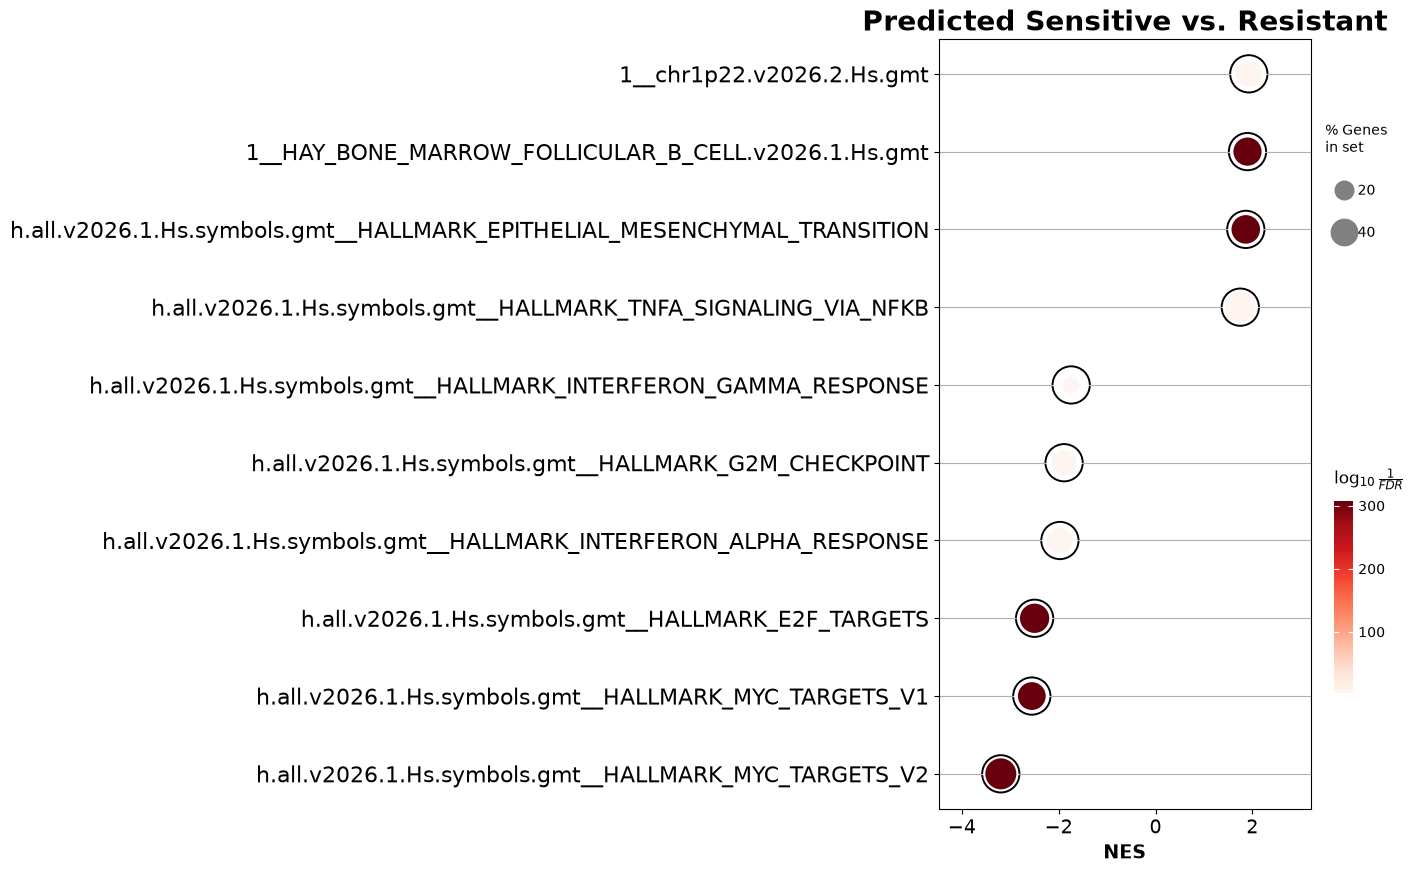

In [ ]:
degs_pred_labels = differential_expression_analysis(mf_ad.to_df().loc[cv_results.index], cv_results, group_label='y_pred')




degs_pred_labels = degs_pred_labels.sort_values(by="t")
pre_res = gp.prerank(rnk=degs_pred_labels, gene_sets=[hallmark_gmt, feature_sets, msig_gmt], threads=8, min_size=5, max_size=1500, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")

plt.clf()
gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='Predicted Sensitive vs. Resistant', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True)

**CV results (t11;14) only**

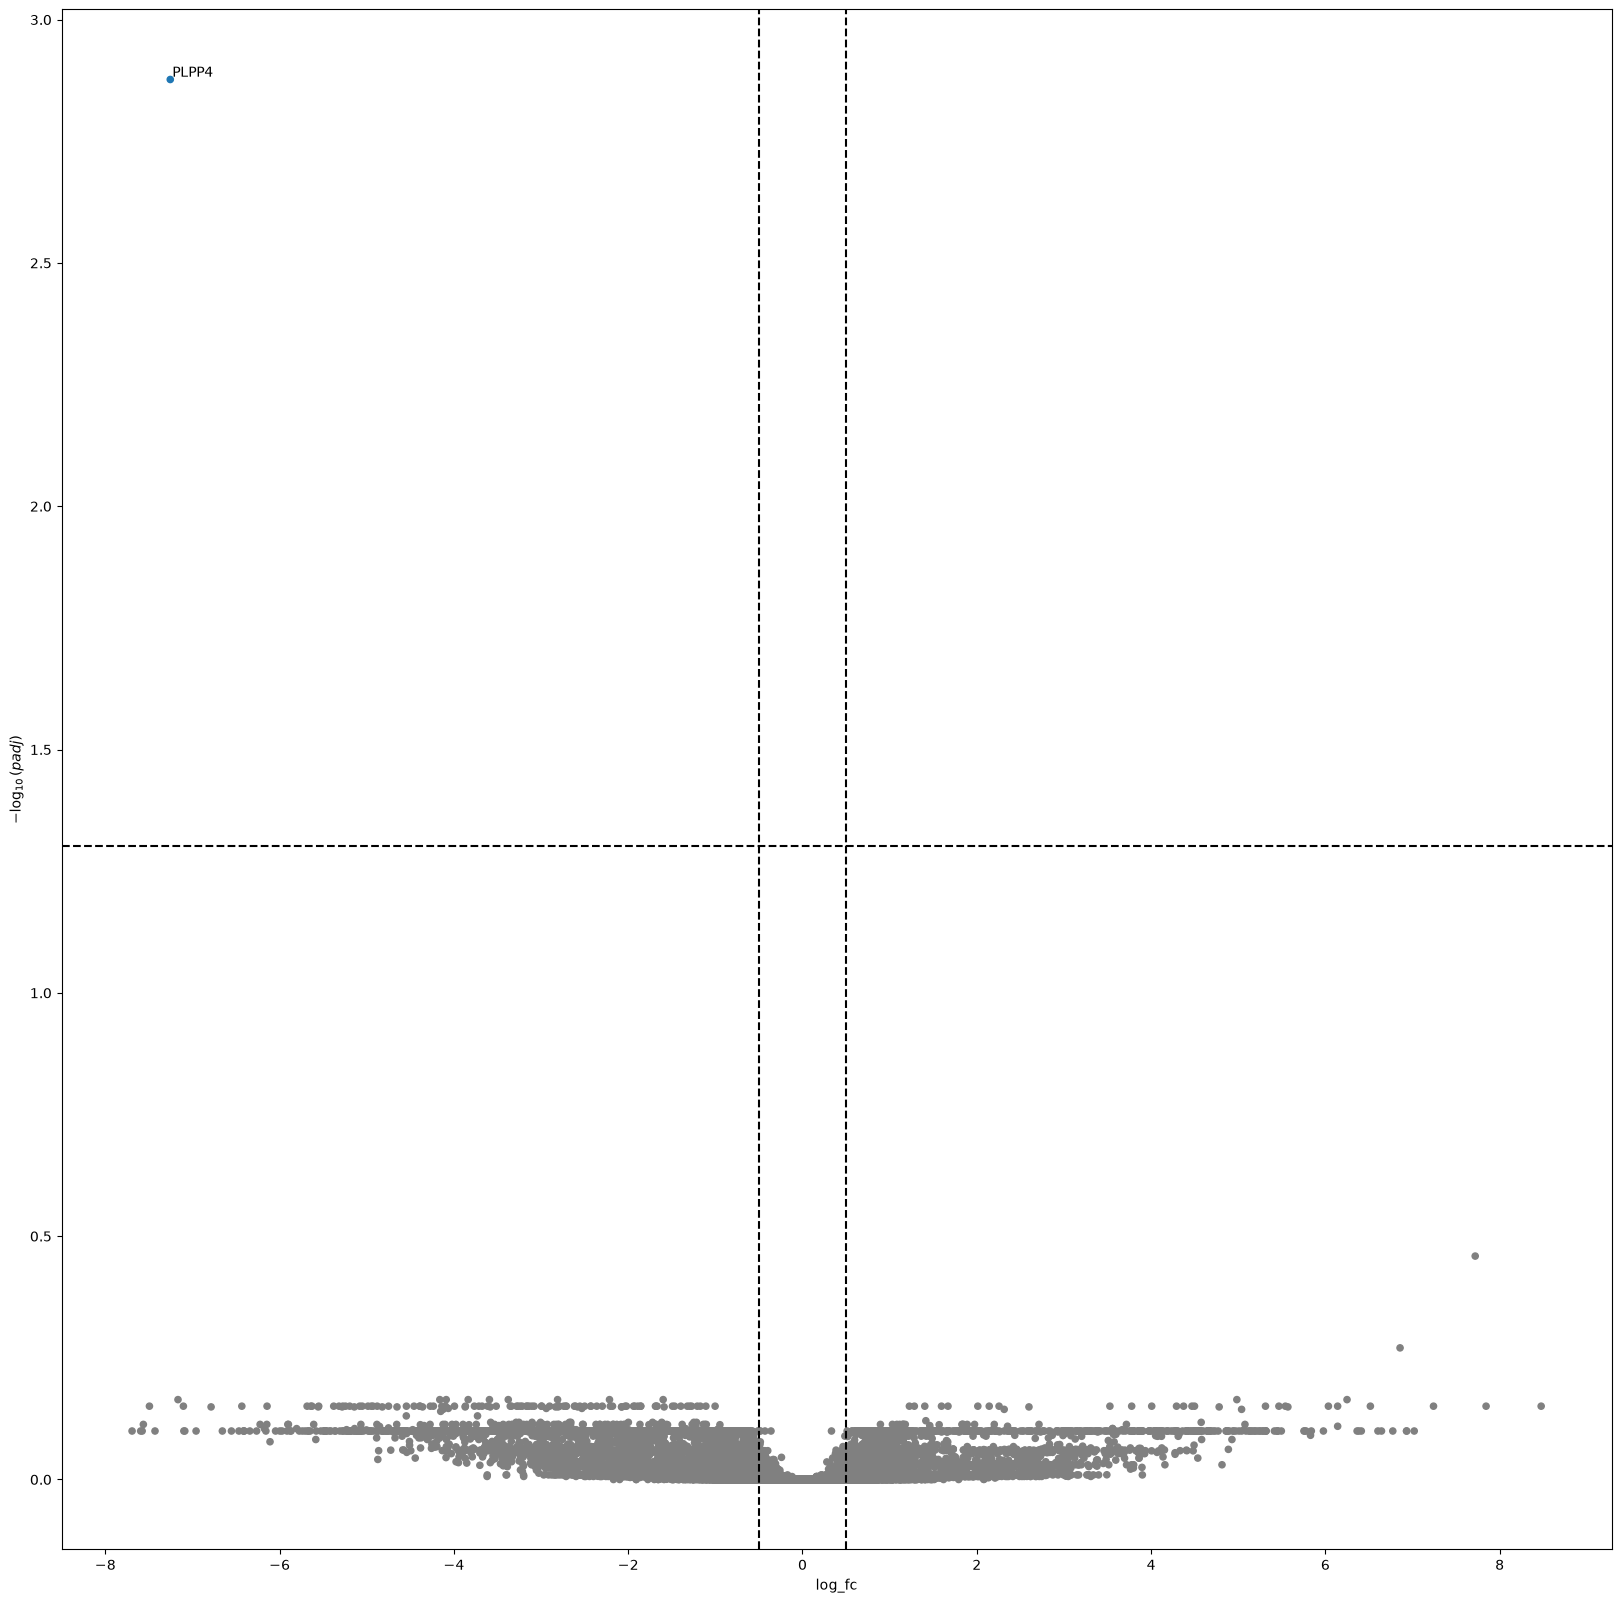

2026-11-04 16:58:22,327 [WARNING] Duplicated values found in preranked stats:
sample	ratio
t        12.59%
padj     95.65%
log_fc   13.26%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'True Sensitive vs. Resistant (t11;14 only)'}, xlabel='NES'>

<Figure size 640x480 with 0 Axes>

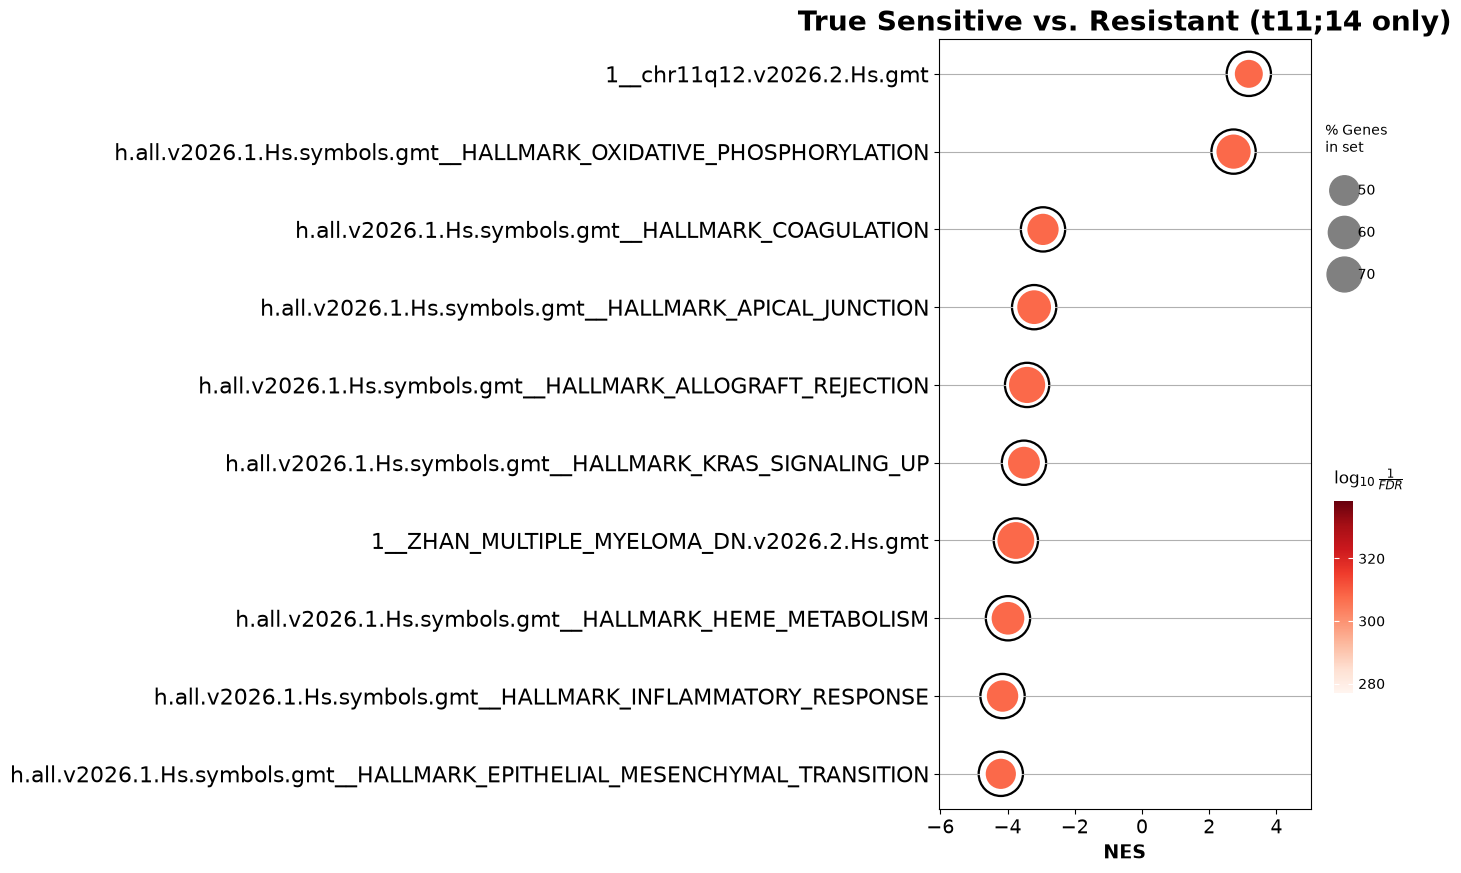

In [ ]:
cv_results_t11_14 = cv_results[cv_results['t11_14'] == 1]

degs_true_labels = differential_expression_analysis(mf_ad.to_df().loc[cv_results_t11_14.index], cv_results_t11_14, group_label='y_true')
degs_true_labels




degs_true_labels = degs_true_labels.sort_values(by="t")
pre_res = gp.prerank(rnk=degs_true_labels, gene_sets=[hallmark_gmt, feature_sets,msig_gmt], threads=8, min_size=5, max_size=1500, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")

plt.clf()
gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='True Sensitive vs. Resistant (t11;14 only)', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True)

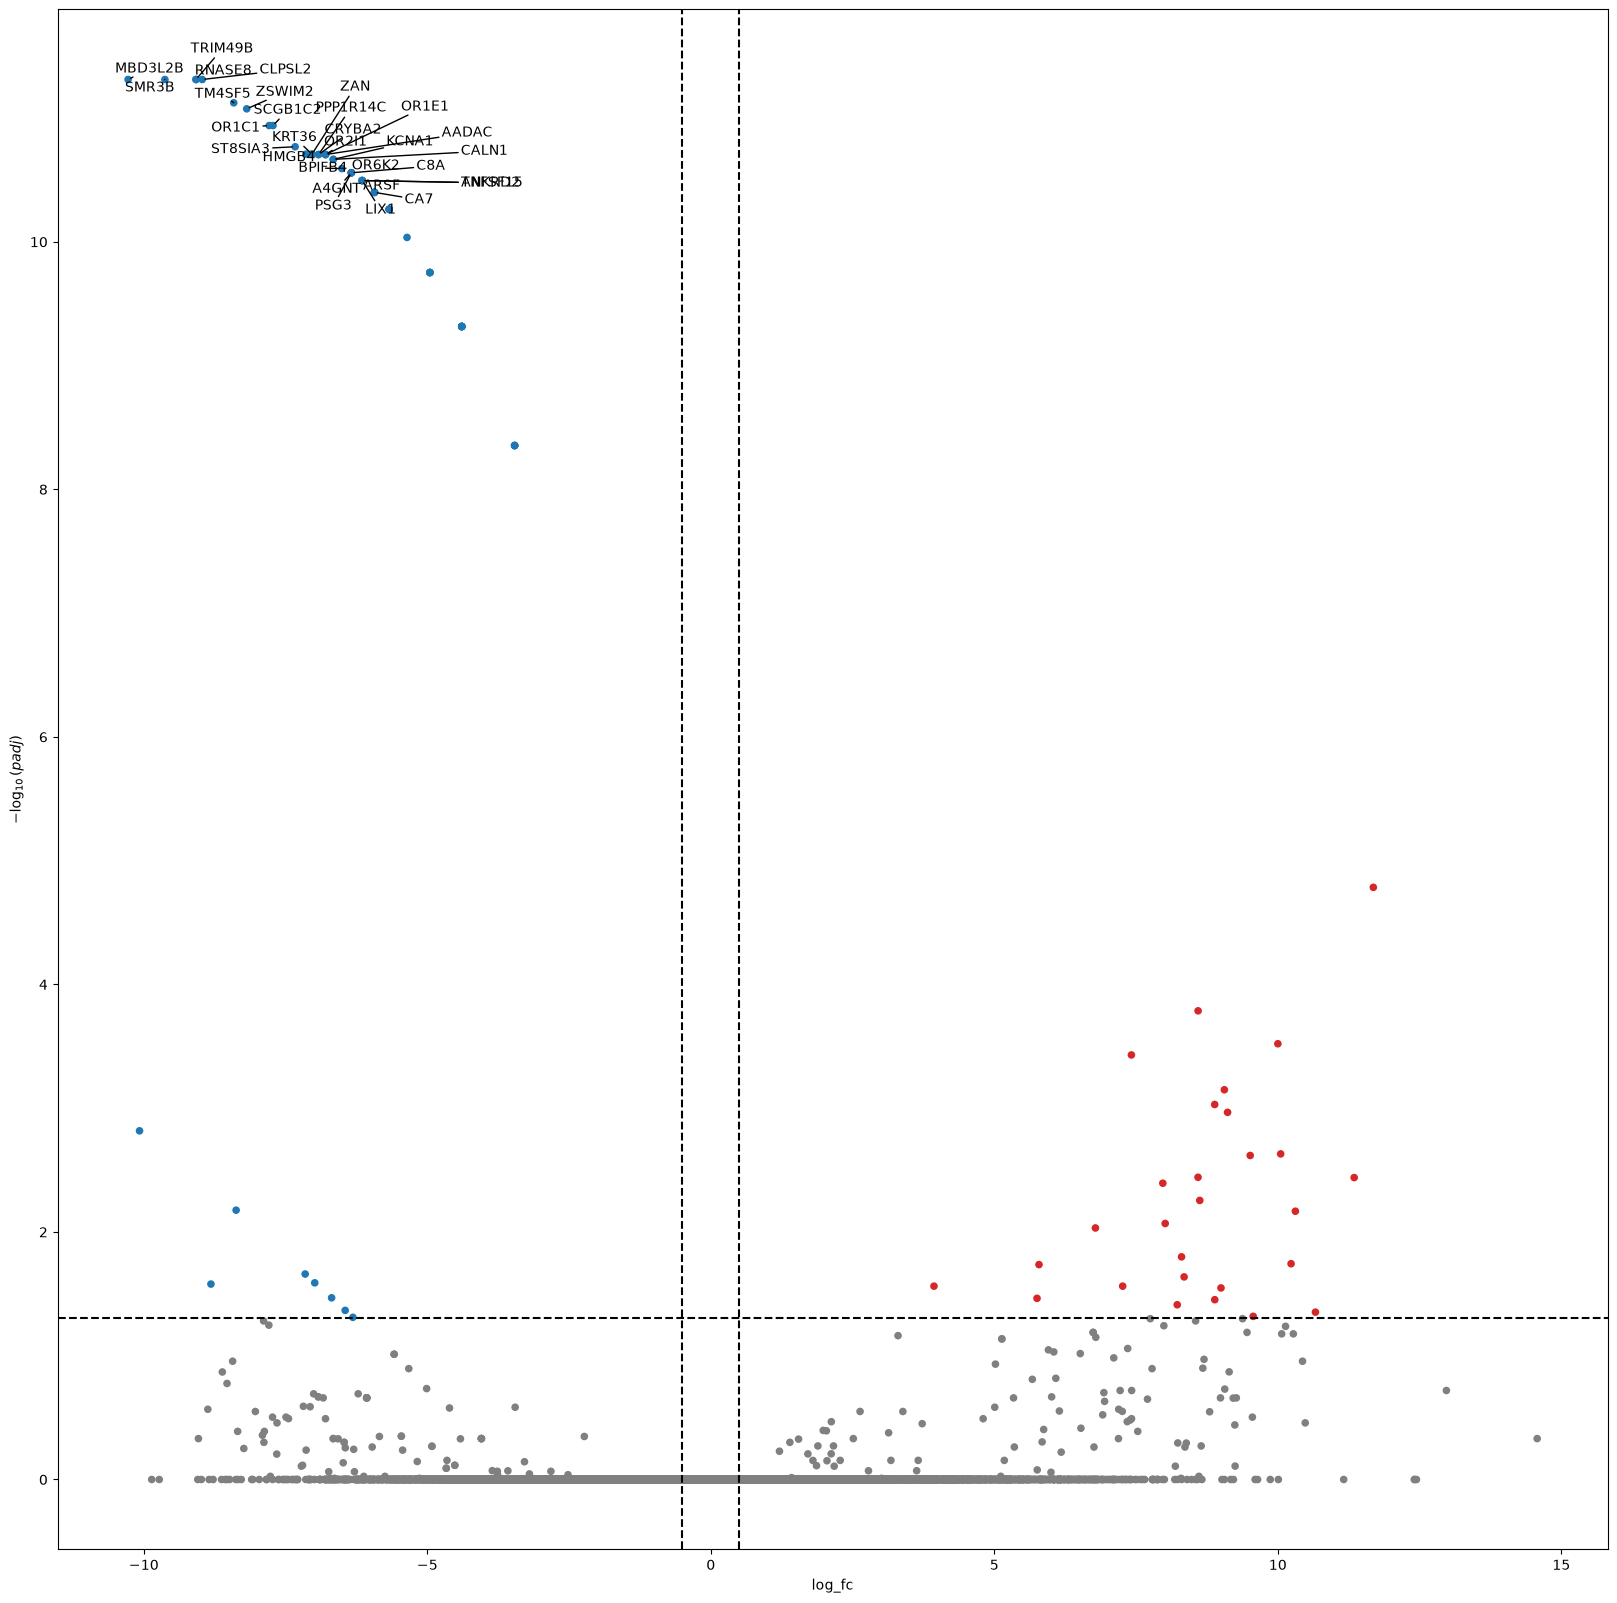

2026-11-04 16:58:37,604 [WARNING] Duplicated values found in preranked stats:
sample	ratio
t        12.92%
padj     99.12%
log_fc   13.50%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'Predicted Sensitive vs. Resistant (t11;14 only)'}, xlabel='NES'>

<Figure size 640x480 with 0 Axes>

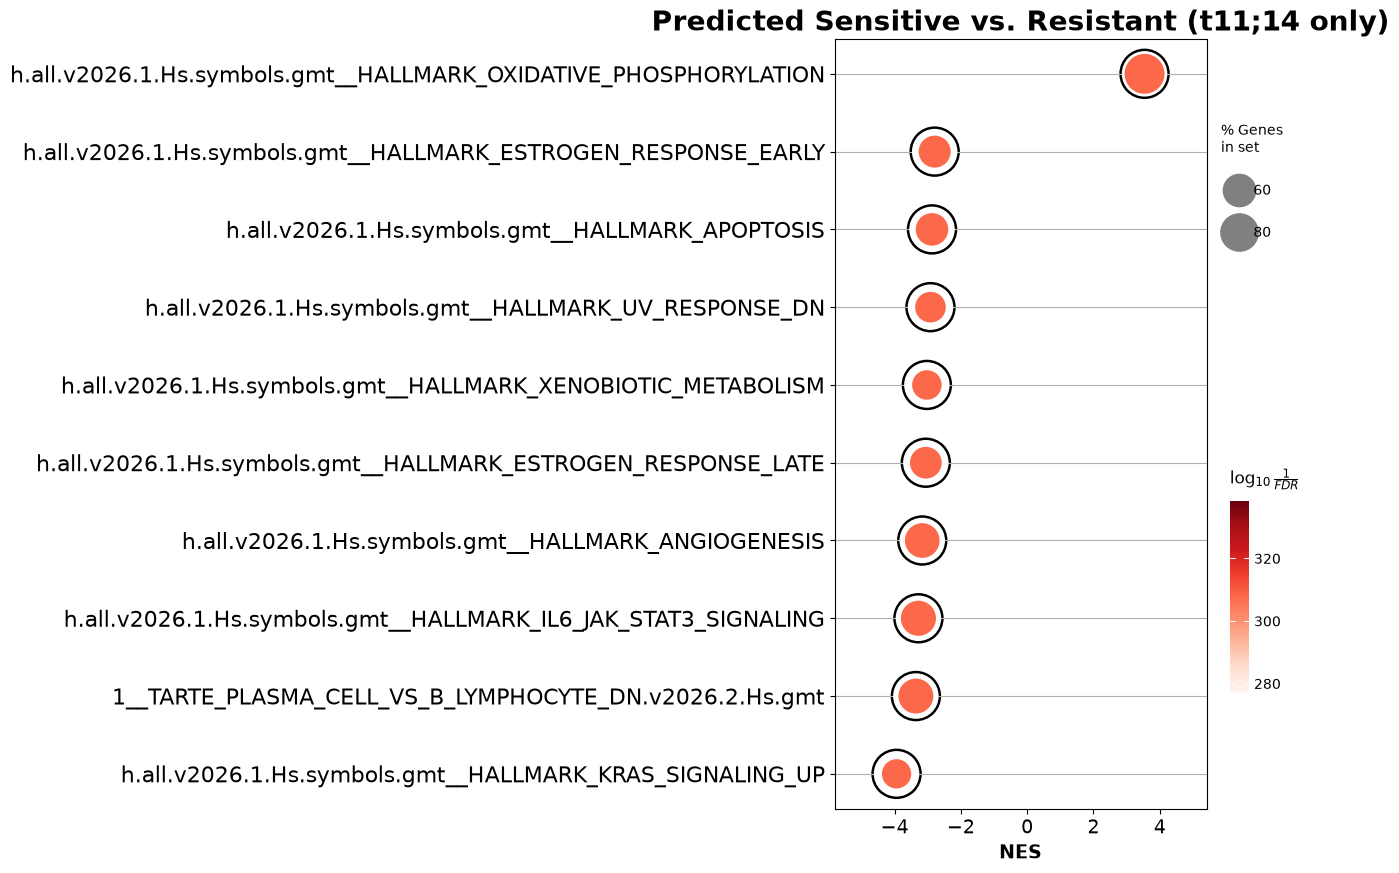

In [ ]:

degs_pred_labels = differential_expression_analysis(mf_ad.to_df().loc[cv_results_t11_14.index], cv_results_t11_14, group_label='y_pred')
degs_pred_labels 


degs_pred_labels  = degs_pred_labels .sort_values(by="t")
pre_res = gp.prerank(rnk=degs_pred_labels, gene_sets=[hallmark_gmt, feature_sets, msig_gmt], threads=8, min_size=5, max_size=1500, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")

plt.clf()
gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='Predicted Sensitive vs. Resistant (t11;14 only)', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True)

**CV results (non-t11;14) only**

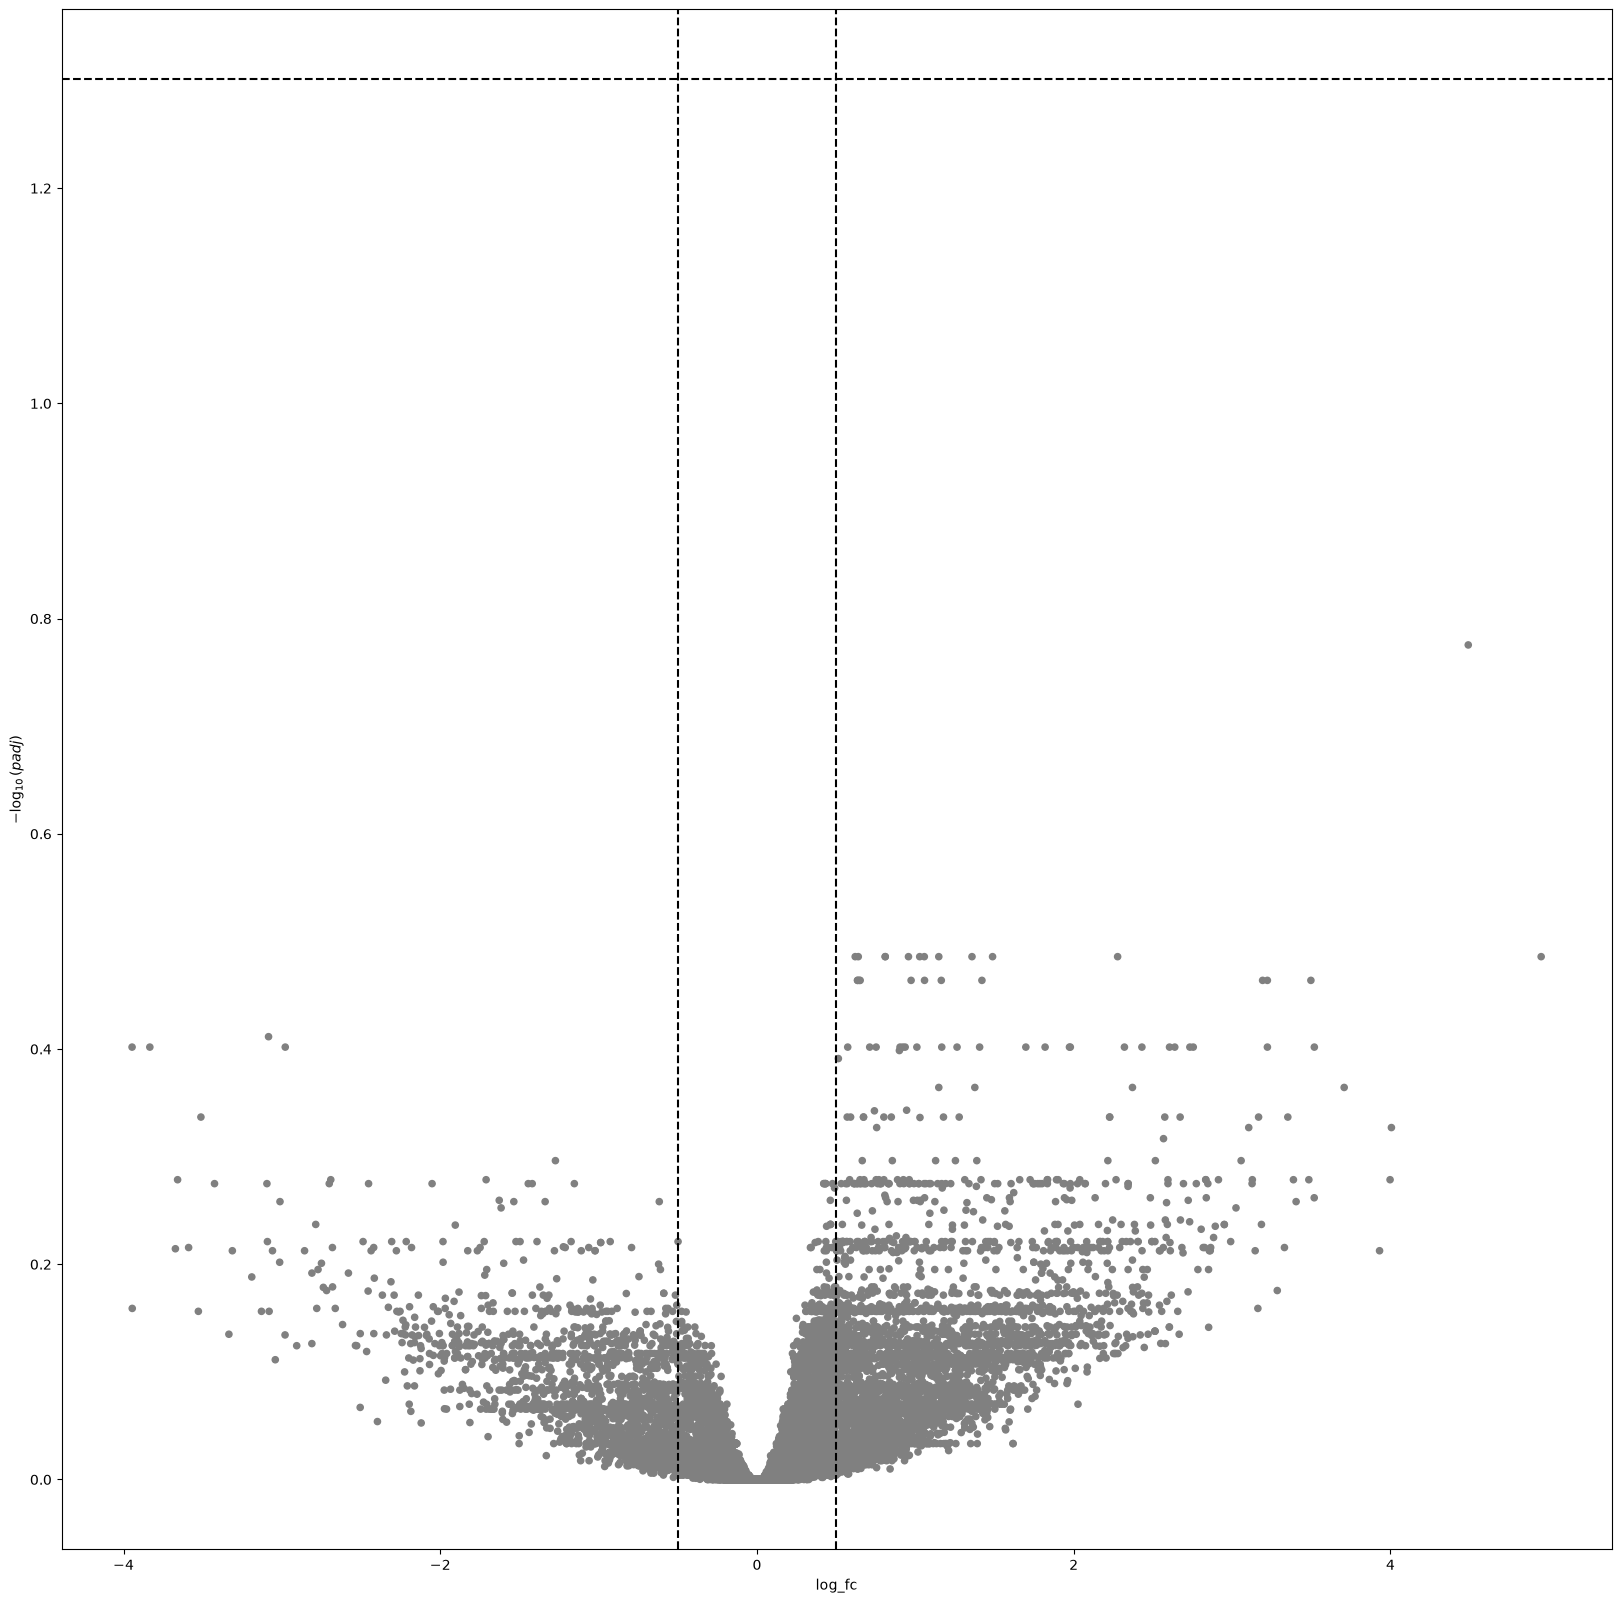

2026-11-04 17:01:54,661 [WARNING] Duplicated values found in preranked stats:
sample	ratio
t         6.07%
padj     90.50%
log_fc    6.54%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'True Sensitive vs. Resistant (non-t11;14 only)'}, xlabel='NES'>

<Figure size 640x480 with 0 Axes>

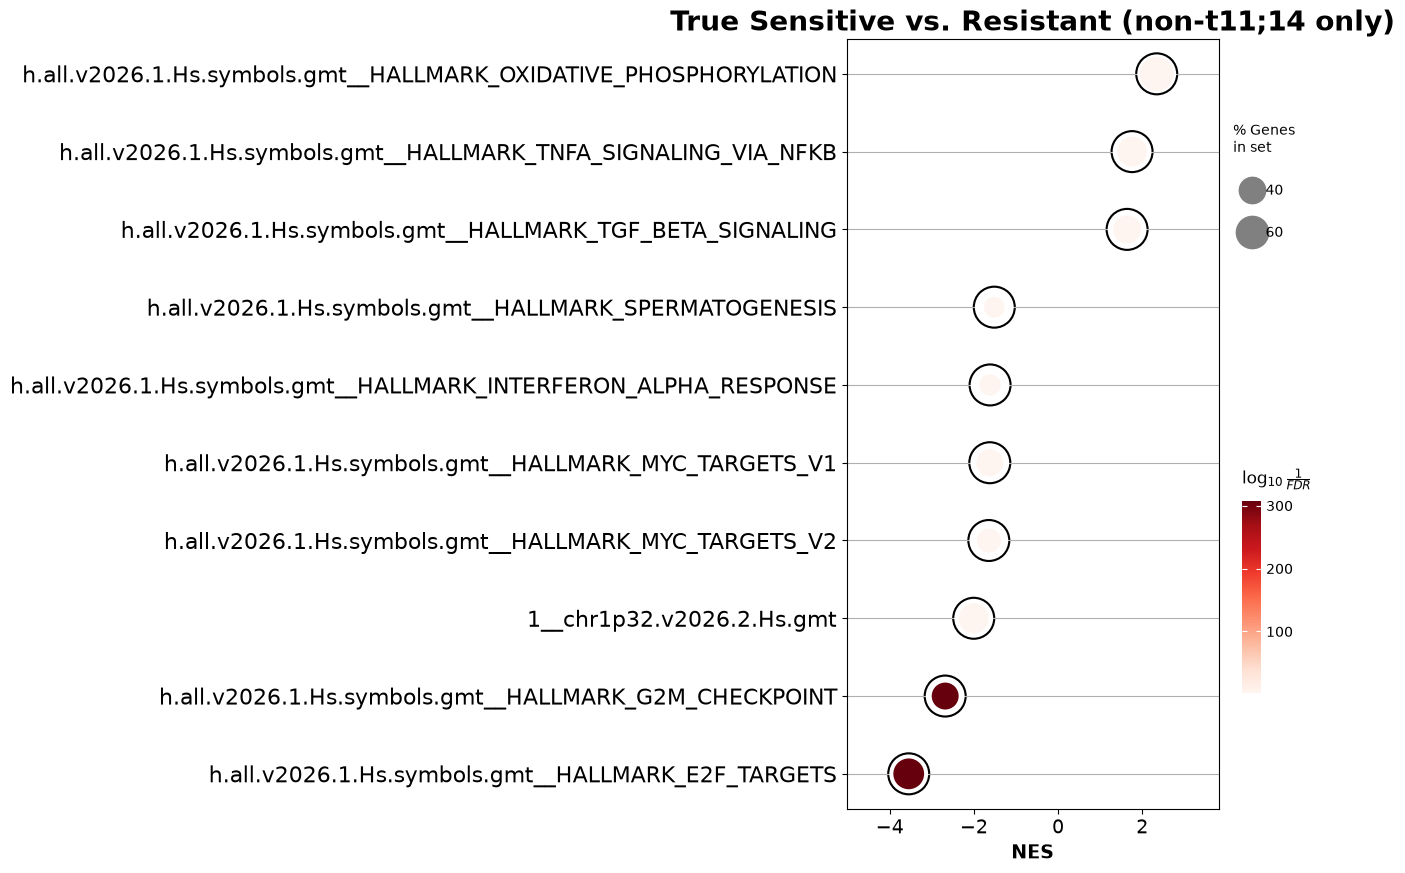

In [ ]:
cv_results_non_t11_14 = cv_results[cv_results['t11_14'] == 0]

degs_true_labels = differential_expression_analysis(mf_ad.to_df().loc[cv_results_non_t11_14.index], cv_results_non_t11_14 , group_label='y_true')


degs_true_labels  = degs_true_labels.sort_values(by="t")
pre_res = gp.prerank(rnk=degs_true_labels, gene_sets=[hallmark_gmt, feature_sets, msig_gmt], threads=8, min_size=5, max_size=1500, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")

plt.clf()
gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='True Sensitive vs. Resistant (non-t11;14 only)', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True)

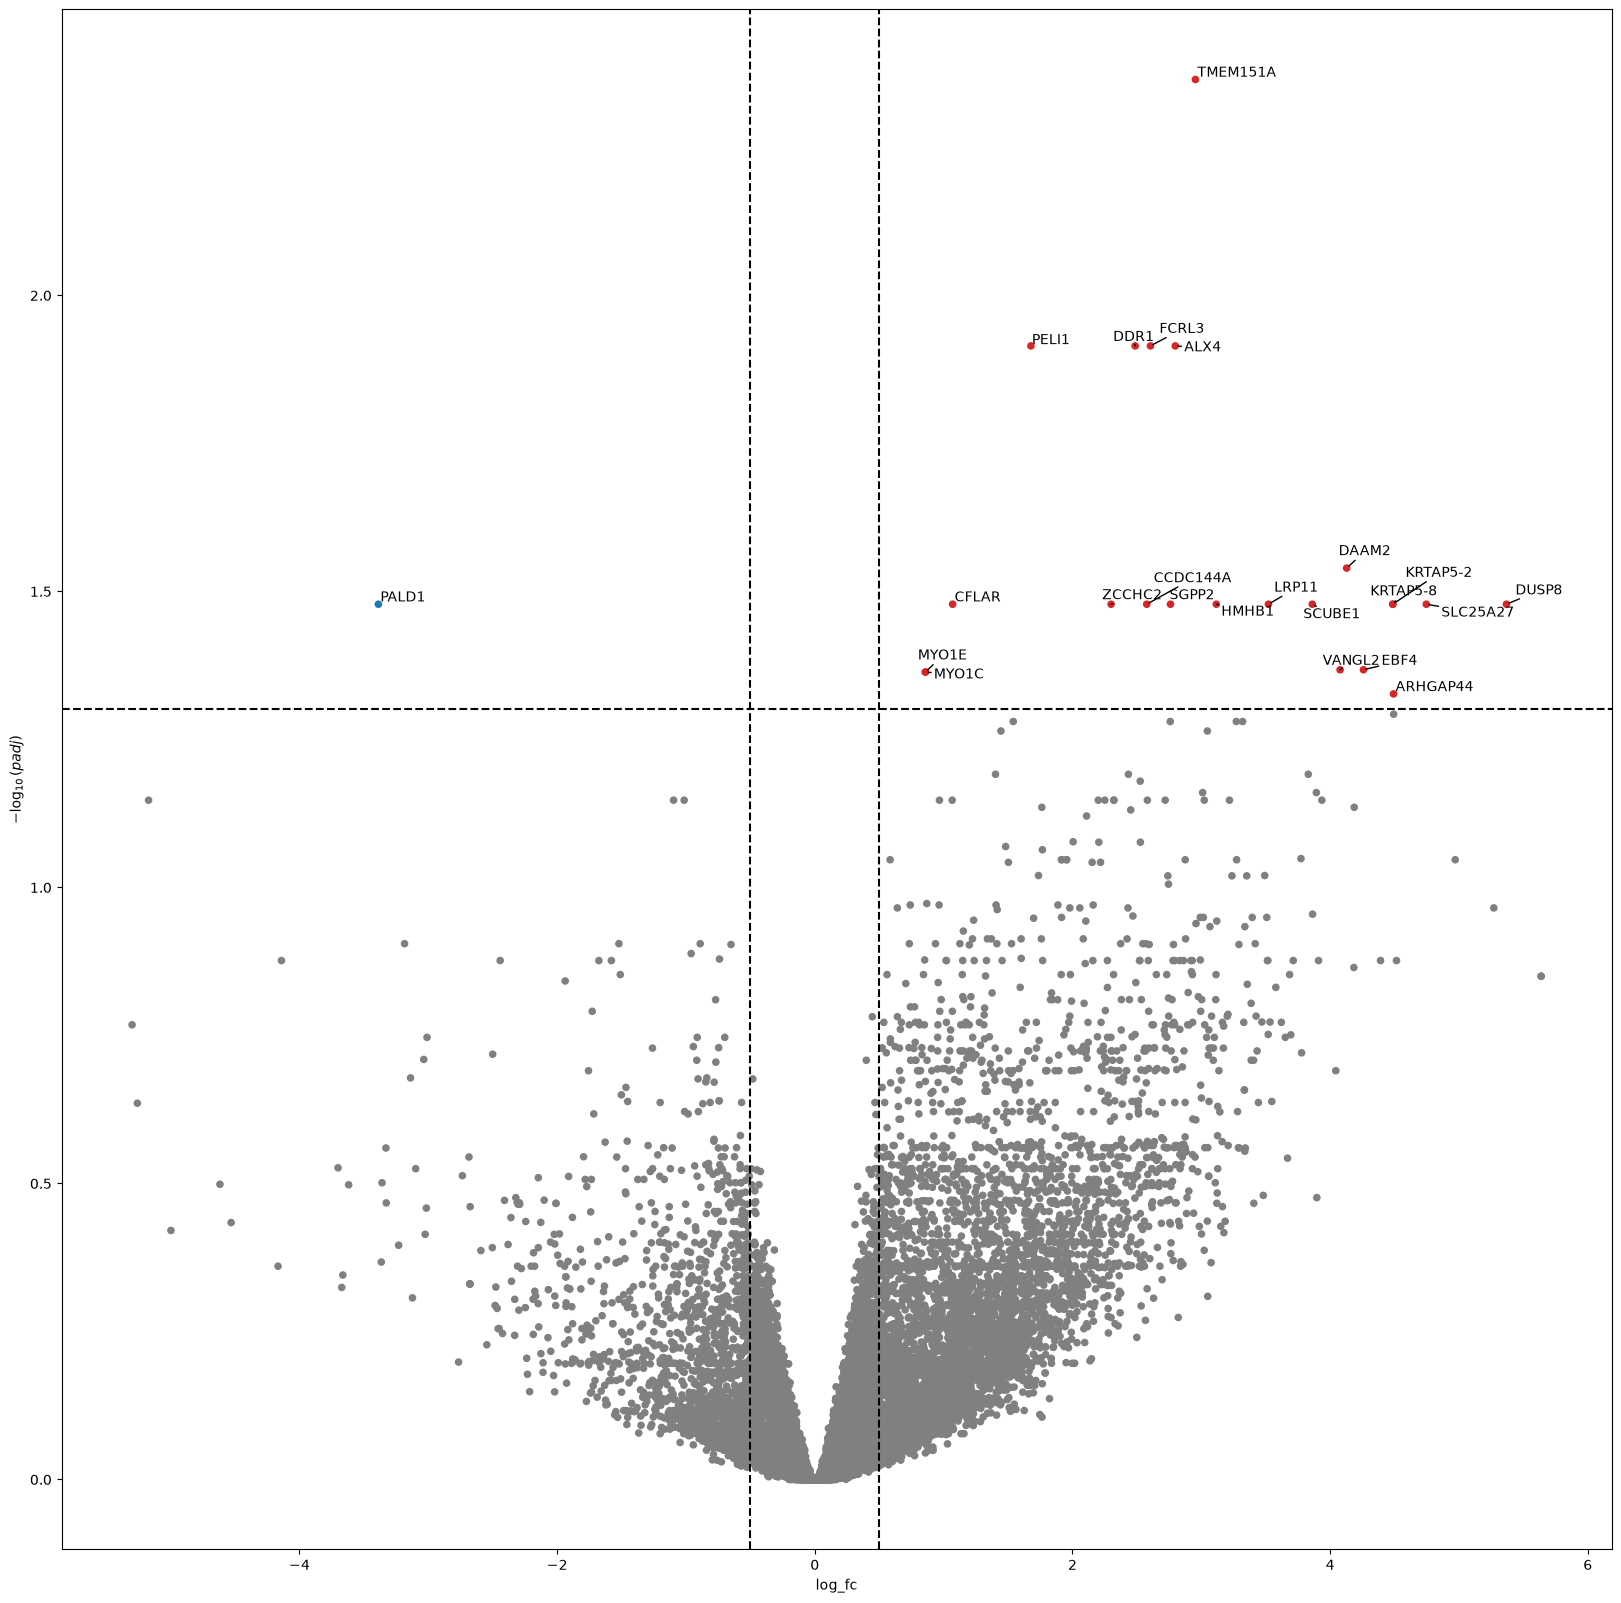

2026-11-04 16:59:05,961 [WARNING] Duplicated values found in preranked stats:
sample	ratio
t         5.87%
padj     76.41%
log_fc    6.35%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'Predicted Sensitive vs. Resistant (non-t11;14 only)'}, xlabel='NES'>

<Figure size 640x480 with 0 Axes>

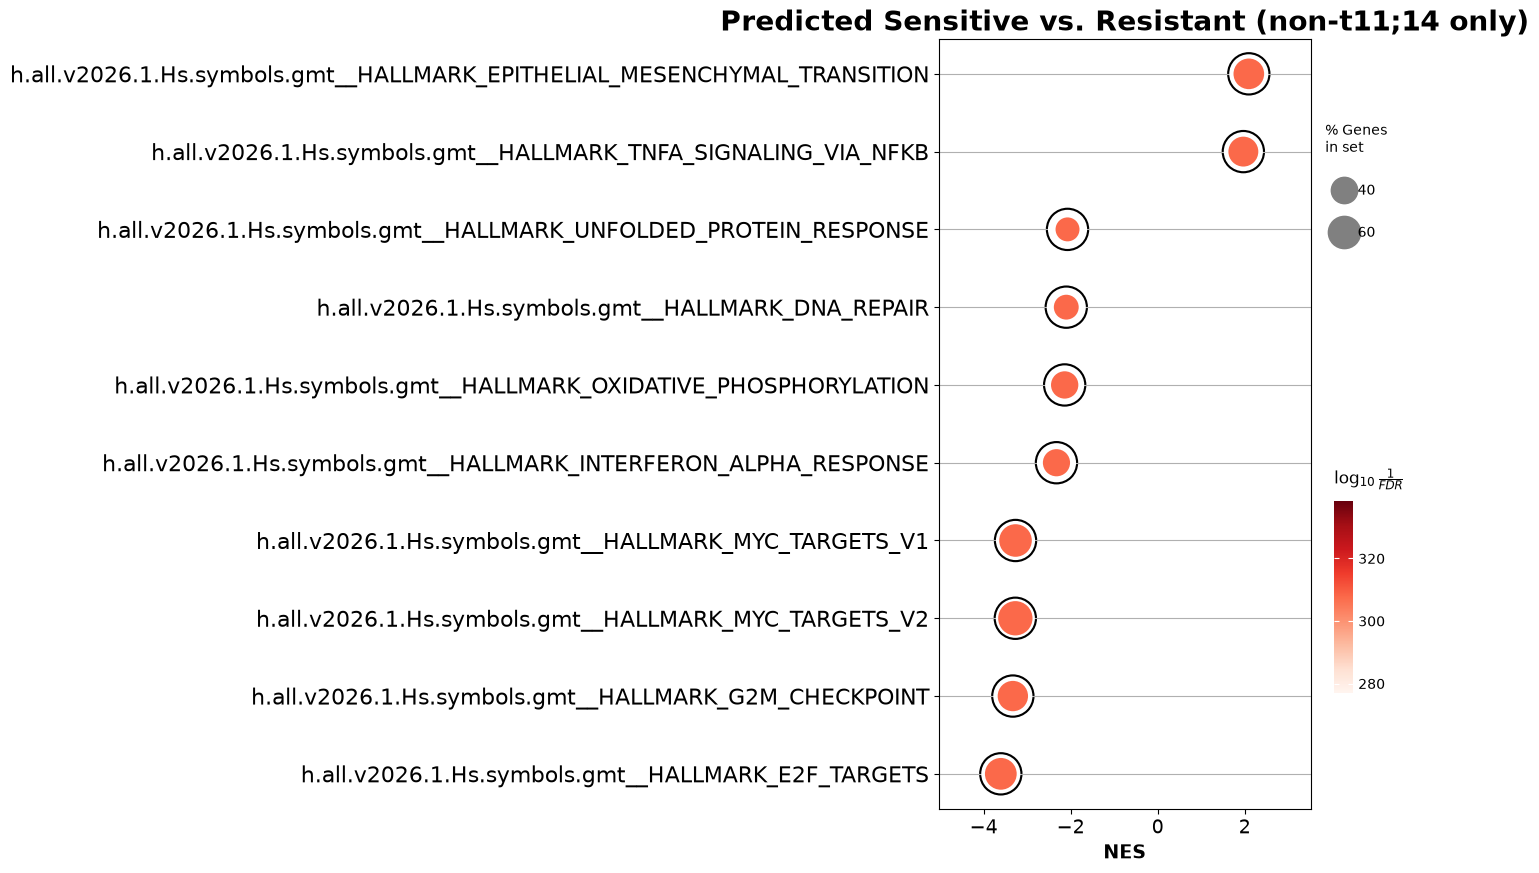

In [ ]:
cv_results_non_t11_14 = cv_results[cv_results['t11_14'] == 0]

degs_pred_labels = differential_expression_analysis(mf_ad.to_df().loc[cv_results_non_t11_14.index], cv_results_non_t11_14 , group_label='y_pred')


degs_pred_labels   = degs_pred_labels.sort_values(by="t")
pre_res = gp.prerank(rnk=degs_pred_labels, gene_sets=[hallmark_gmt, feature_sets, msig_gmt], threads=8, min_size=5, max_size=1500, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")

plt.clf()
gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='Predicted Sensitive vs. Resistant (non-t11;14 only)', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True)

**t11;14 vs. non-t11;14**

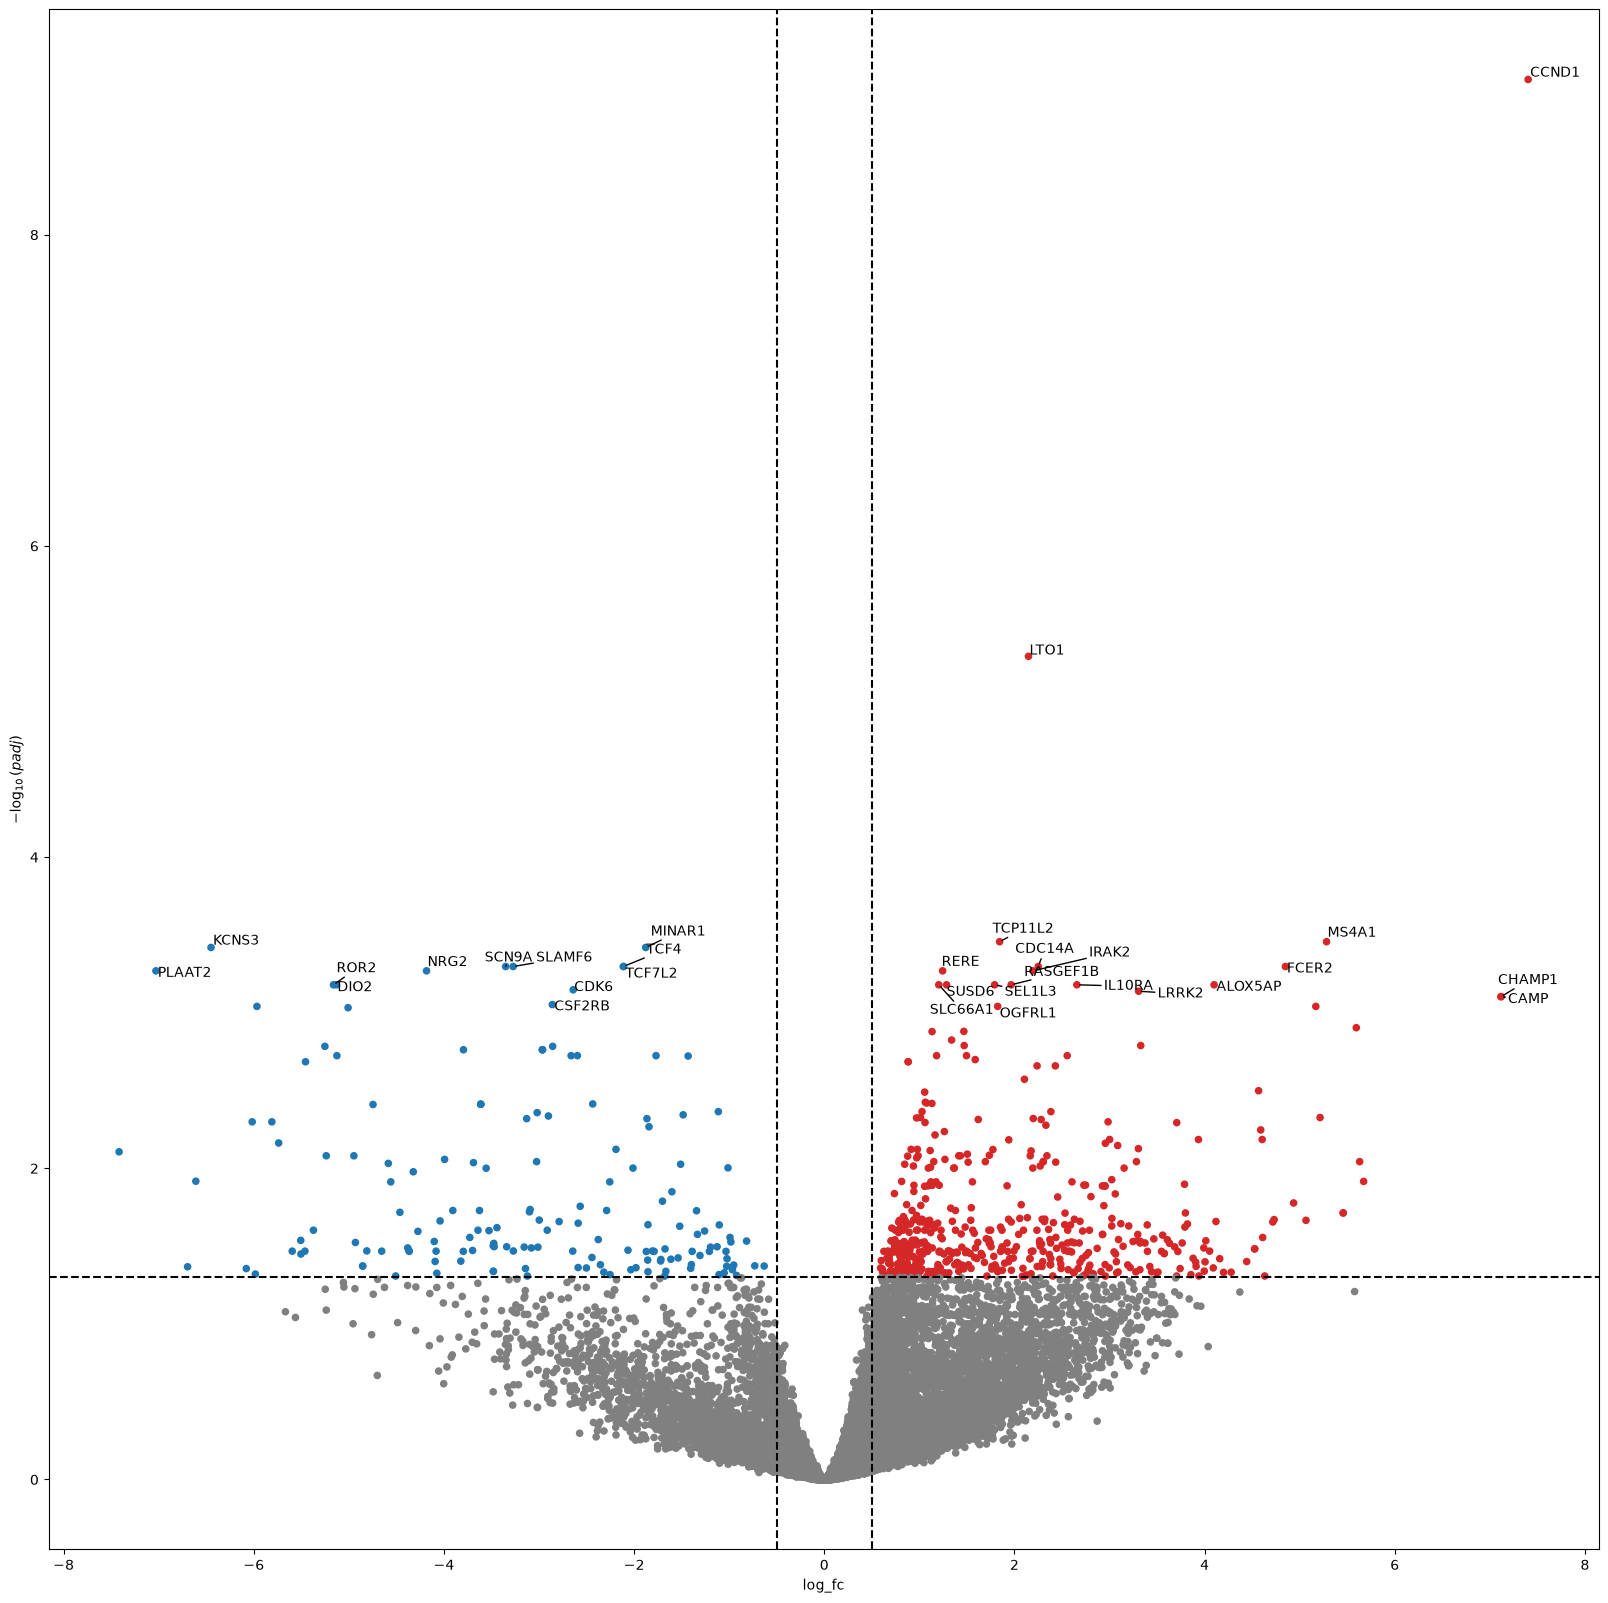

2026-11-04 16:59:19,946 [WARNING] Duplicated values found in preranked stats:
sample	ratio
t         5.50%
padj     57.43%
log_fc    6.14%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 't11;14 vs. non-t11;14'}, xlabel='NES'>

<Figure size 640x480 with 0 Axes>

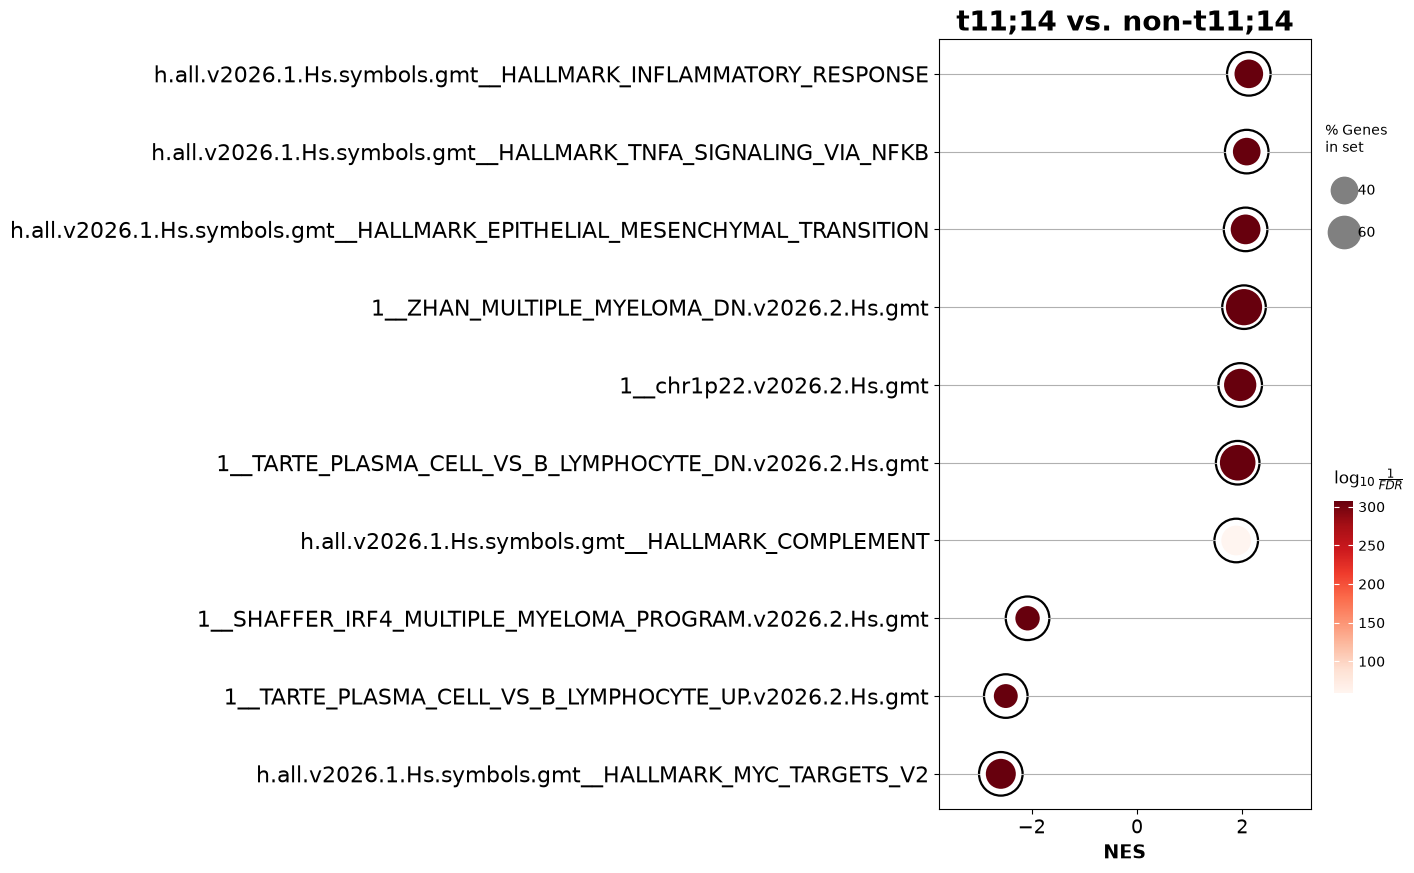

In [ ]:
cv_results = cv_results[cv_results['t11_14'].notna()]

res = differential_expression_analysis(mf_ad.to_df().loc[cv_results.index], cv_results , group_label='t11_14')


res  = res.sort_values(by="t")
pre_res = gp.prerank(rnk=res, gene_sets=[hallmark_gmt, feature_sets, msig_gmt], threads=8, min_size=5, max_size=1500, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")

plt.clf()
gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='t11;14 vs. non-t11;14', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True)

In [19]:
gsea_res = pre_res.res2d.set_index('Term').drop("Name", axis=1)

gsea_res.index

Index(['h.all.v2026.1.Hs.symbols.gmt__HALLMARK_MYC_TARGETS_V2',
       '1__TARTE_PLASMA_CELL_VS_B_LYMPHOCYTE_UP.v2026.2.Hs.gmt',
       'h.all.v2026.1.Hs.symbols.gmt__HALLMARK_OXIDATIVE_PHOSPHORYLATION',
       '1__SHAFFER_IRF4_MULTIPLE_MYELOMA_PROGRAM.v2026.2.Hs.gmt',
       '1__t11_14_degs',
       'h.all.v2026.1.Hs.symbols.gmt__HALLMARK_MYC_TARGETS_V1',
       '1__SHAFFER_IRF4_TARGETS_IN_MYELOMA_VS_MATURE_B_LYMPHOCYTE.v2026.2.Hs.gmt',
       'h.all.v2026.1.Hs.symbols.gmt__HALLMARK_UNFOLDED_PROTEIN_RESPONSE',
       '1__ZHAN_EARLY_DIFFERENTIATION_GENES_UP.v2026.2.Hs.gmt',
       '1__SHAFFER_IRF4_TARGETS_IN_PLASMA_CELL_VS_MATURE_B_LYMPHOCYTE.v2026.2.Hs.gmt',
       '1__SHAFFER_IRF4_TARGETS_IN_ACTIVATED_B_LYMPHOCYTE.v2026.2.Hs.gmt',
       '1__ZHAN_MULTIPLE_MYELOMA_UP.v2026.2.Hs.gmt',
       '1__SHAFFER_IRF4_TARGETS_IN_ACTIVATED_DENDRITIC_CELL.v2026.2.Hs.gmt',
       'h.all.v2026.1.Hs.symbols.gmt__HALLMARK_MTORC1_SIGNALING',
       '1__ZHAN_LATE_DIFFERENTIATION_GENES_UP.v2026.2.Hs.gmt'

**Analyzing External Validation Results**

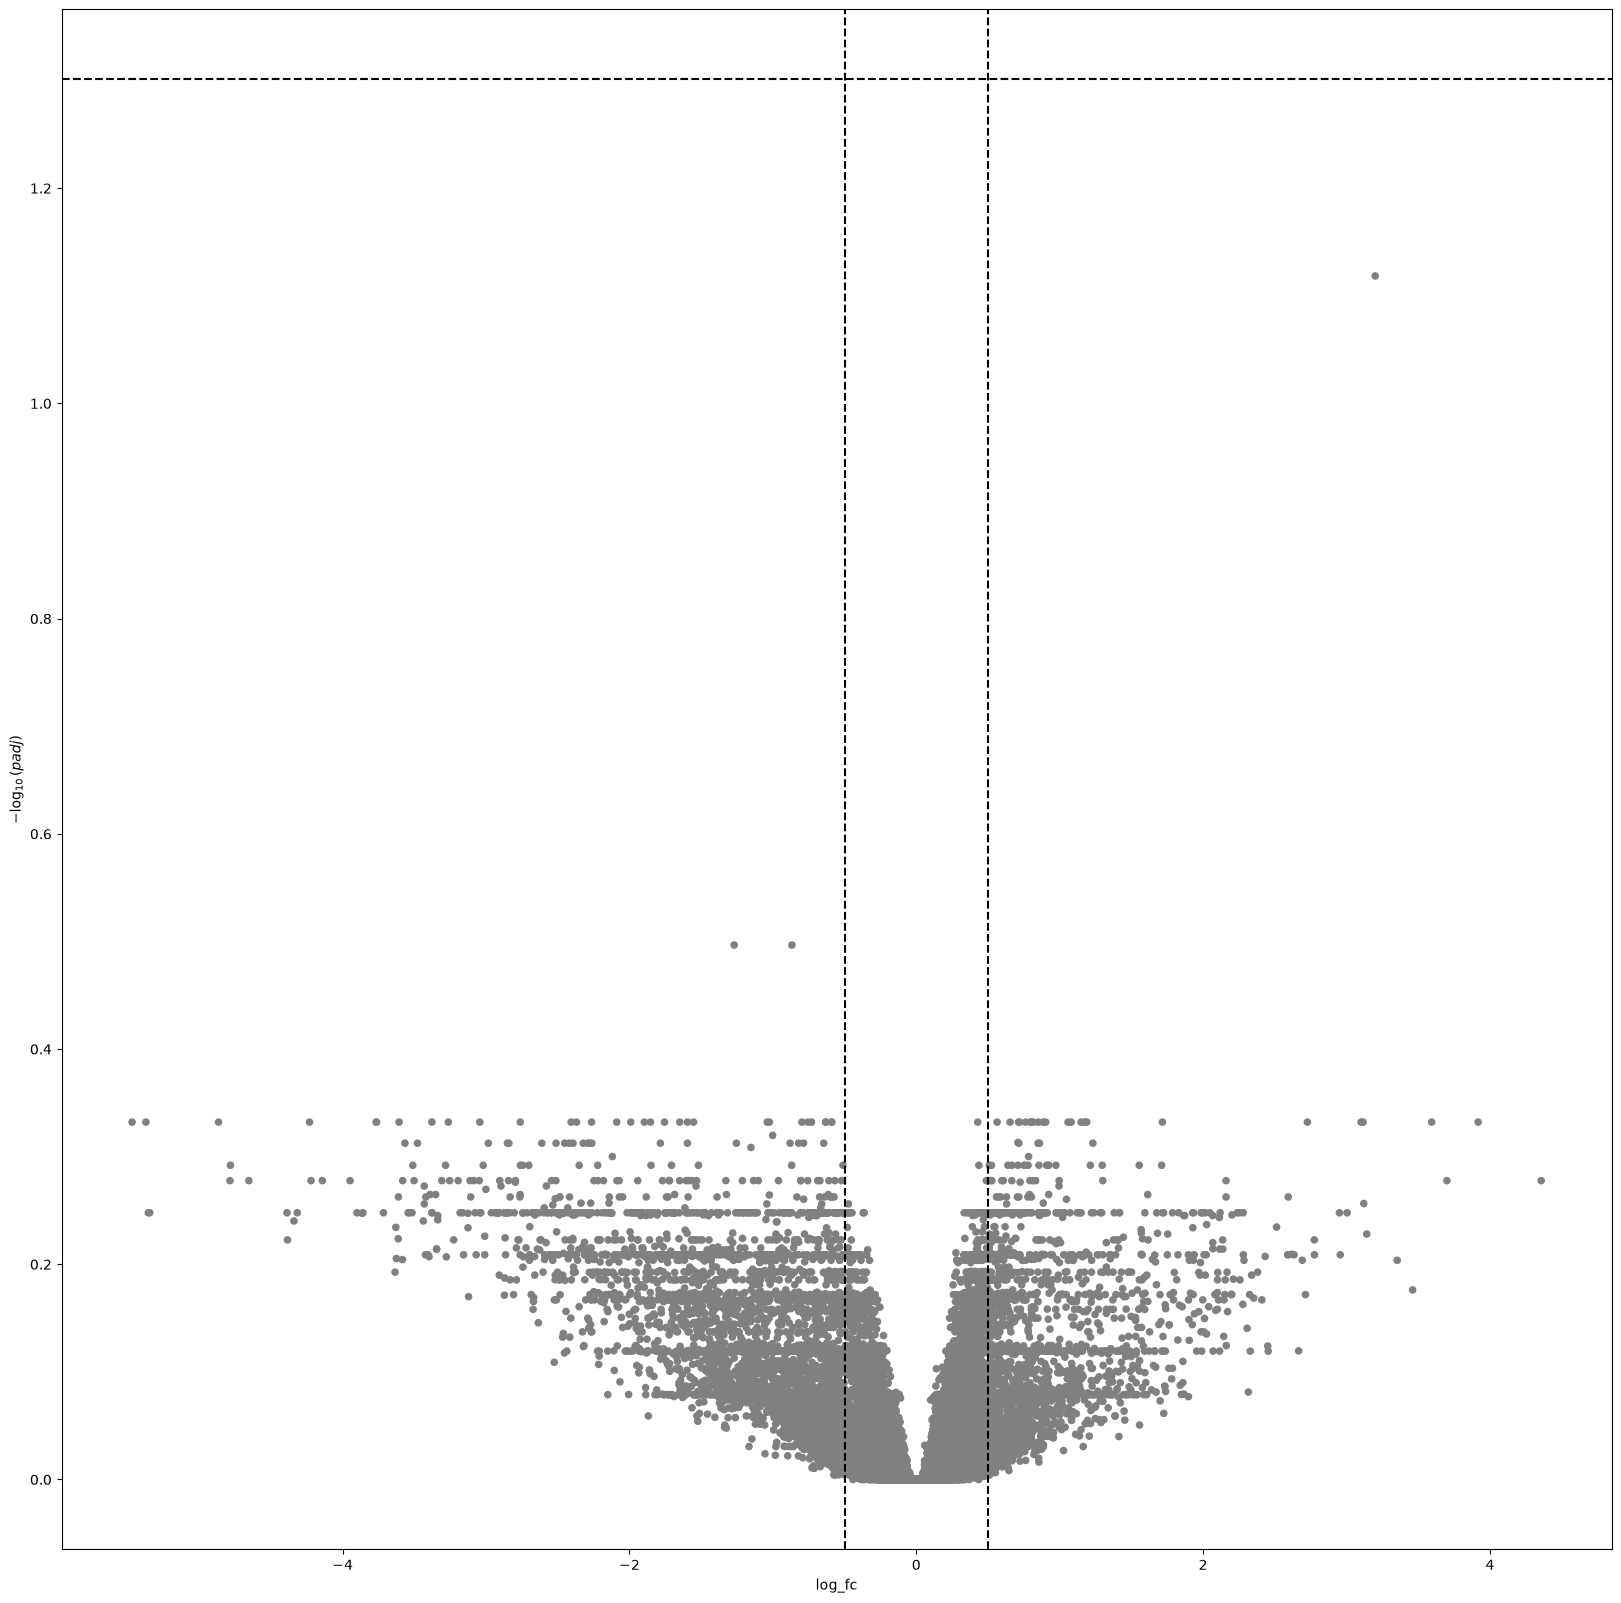

2026-11-04 16:59:34,552 [WARNING] Duplicated values found in preranked stats:
sample	ratio
t         4.86%
padj     87.89%
log_fc    4.86%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'True Sensitive vs. Resistant'}, xlabel='NES'>

<Figure size 640x480 with 0 Axes>

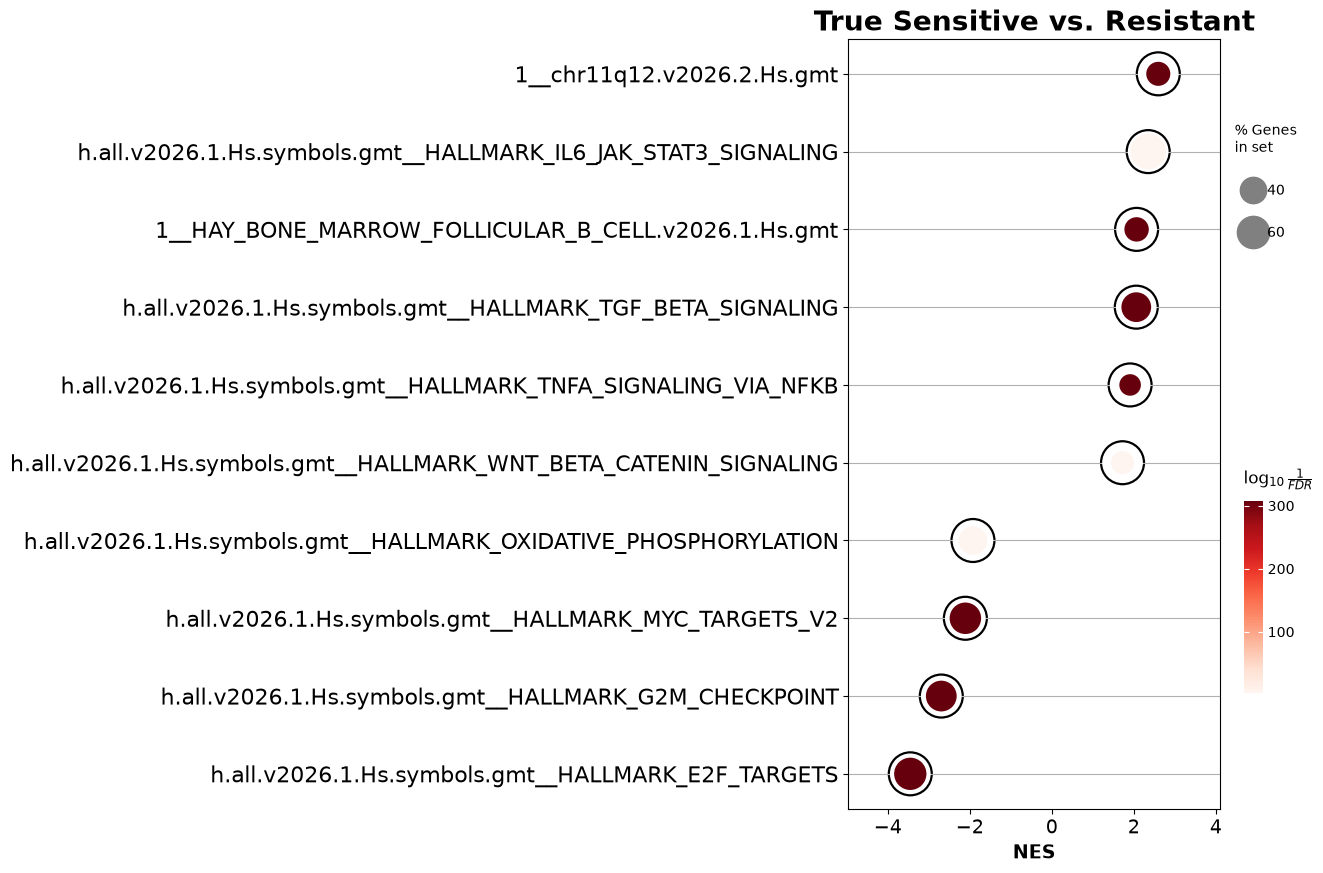

In [ ]:
degs_true_labels = differential_expression_analysis(dc_ad.to_df().loc[ev_results.index], ev_results, group_label='y_true')

degs_true_labels = degs_true_labels.sort_values(by="t")
pre_res = gp.prerank(rnk=degs_true_labels, gene_sets=[hallmark_gmt, feature_sets, msig_gmt], threads=8, min_size=5, max_size=1500, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")

plt.clf()
gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='True Sensitive vs. Resistant', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True)


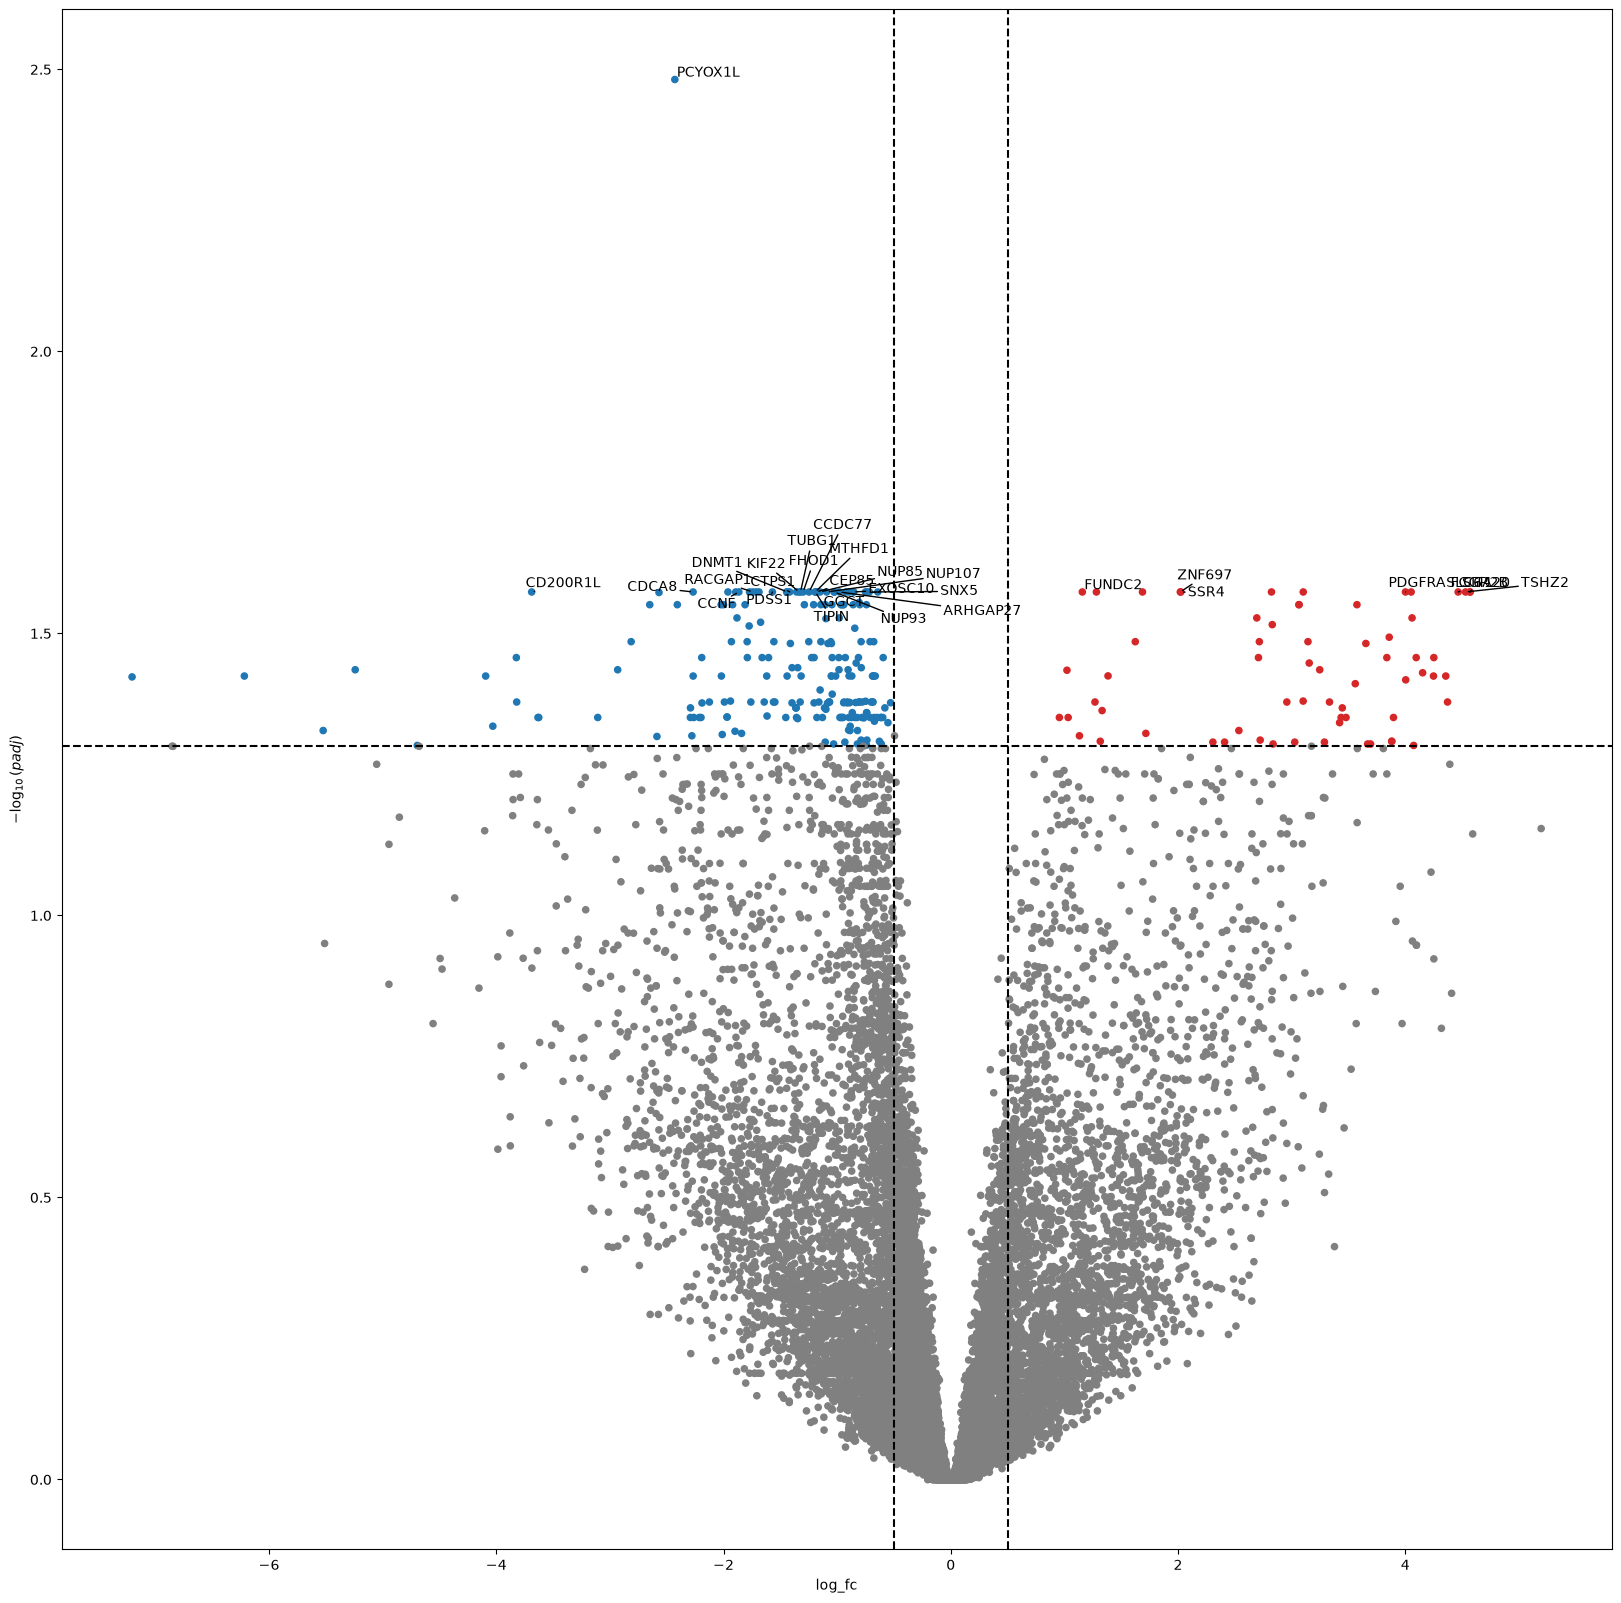

2026-11-04 16:59:50,054 [WARNING] Duplicated values found in preranked stats:
sample	ratio
t         4.86%
padj     65.07%
log_fc    4.86%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'Predicted Sensitive vs. Resistant'}, xlabel='NES'>

<Figure size 640x480 with 0 Axes>

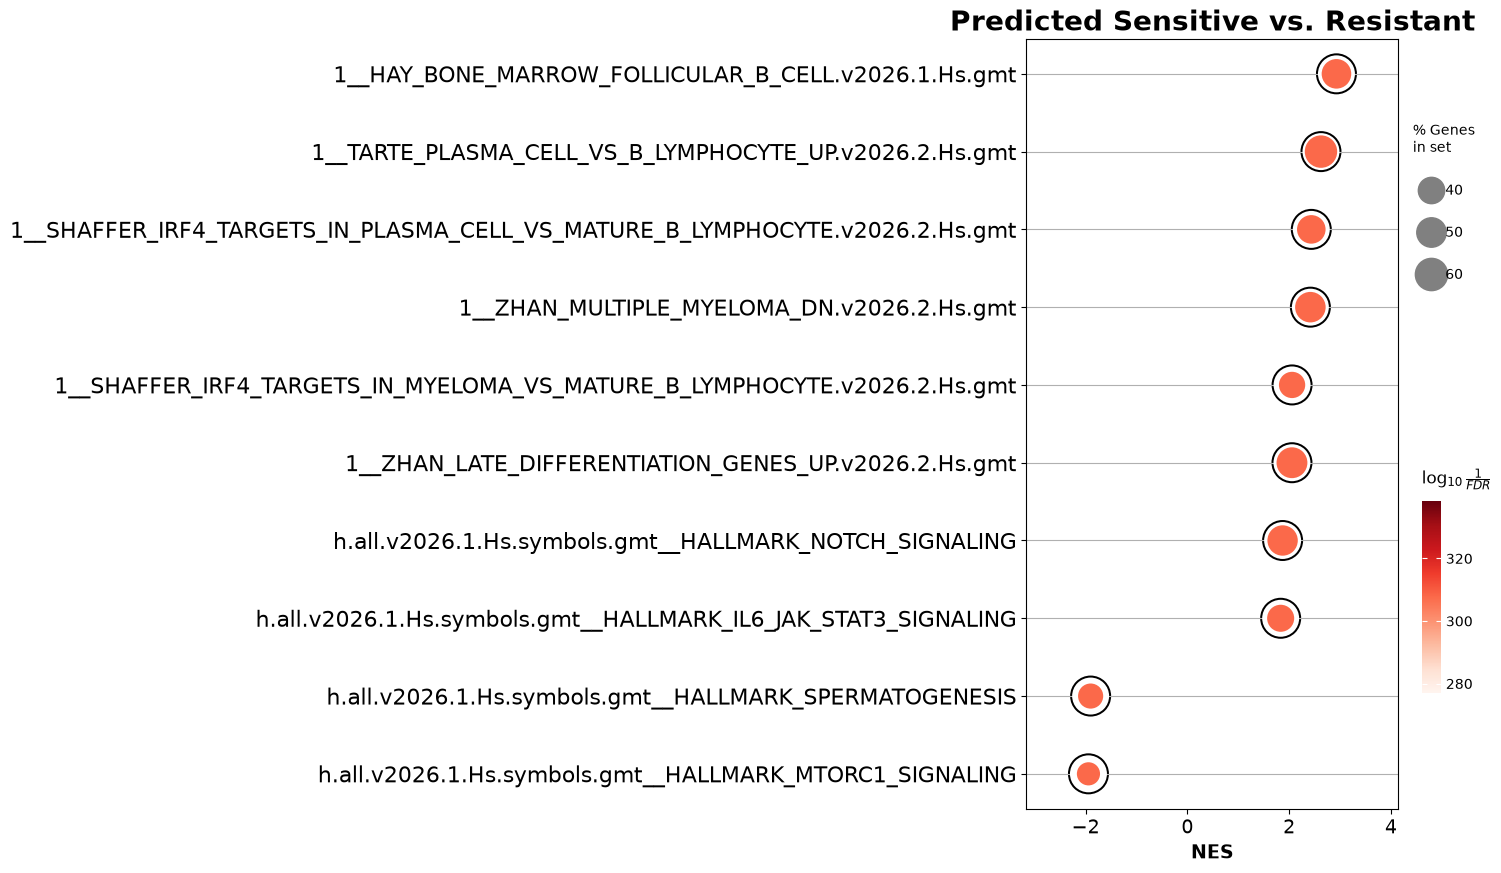

In [ ]:
degs_pred_labels = differential_expression_analysis(dc_ad.to_df().loc[ev_results.index], ev_results, group_label='y_pred')

degs_pred_labels = degs_pred_labels.sort_values(by="t")
pre_res = gp.prerank(rnk=degs_pred_labels, gene_sets=[hallmark_gmt, feature_sets, msig_gmt], threads=8, min_size=5, max_size=1500, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")

plt.clf()
gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='Predicted Sensitive vs. Resistant', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True)